# Credit Card Fraud Detection 2026 (versi perbaikan)

Notebook ini adalah versi perbaikan dari `cc_fraud_project.ipynb`. Alurnya tetap sama, ditambah:

1. **Perbaikan perhitungan** (setiap sel yang diubah diberi tanda **[PERBAIKAN]** dan alasannya).
2. **Perbandingan model yang adil**: semua model memakai data split yang sama, tuning hyperparameter dengan cross-validation di data latih, dan threshold dipilih berdasarkan **total biaya** dari prediksi cross-validation (bukan dari data uji).
3. **Model final**: ROC-AUC, PR-AUC, Feature Importance, dan SHAP.

Ringkasan perbaikan ada di bagian paling akhir notebook.

# 1 LOAD LIBRARY & GENERAL CLEANING

Pada tahap ini akan dilakukan langkah demi langkah untuk load library kebutuhan data analisis, mempelajari studi literatur mengenai kolom-kolom pada data tersebut untuk pembentukan machine learning di tahapan selanjutnya, kemudian akan dideteksi juga kolom-kolom yang memiliki nilai kosong dan melakukan imputasi sederhana agar data yang digunakkan seluruhnya terisi data

**[PERBAIKAN]** Import `numpy` sebelumnya ditulis dua kali, dan library untuk model tambahan (Gradient Boosting, SHAP) serta metrik ROC-AUC/PR-AUC belum ada. Semua import dikumpulkan di sini.

In [1]:
import os, time, warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn import set_config
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, fbeta_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')   # tampilan default 2 digit desimal
RANDOM_STATE = 42

## 1.1 Load Data

In [2]:
# Cari file data di folder kerja atau satu folder di atasnya
for p in ['credit_card_fraud_detection_2026.csv', '../credit_card_fraud_detection_2026.csv',
          '/mnt/project-files/credit_card_fraud_detection_2026.csv']:
    if os.path.exists(p):
        DATA_PATH = p
        break
df = pd.read_csv(DATA_PATH)
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,...,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,...,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.00
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,...,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.00
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,...,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.00
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,...,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.00
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,...,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.00


## 1.2 Kolom Explanation

## Kamus Data: Credit Card Fraud Detection 2026

Dataset ini berisi 100.000 transaksi kartu kredit sepanjang tahun 2026 dengan 43 kolom.

### 1. Identitas Transaksi
| Kolom | Penjelasan |
|---|---|
| `transaction_id` | ID unik untuk setiap transaksi |
| `customer_id` | ID nasabah |
| `card_id` | ID kartu yang dipakai |
| `merchant_id` | ID merchant atau toko |
| `transaction_datetime` | Tanggal dan jam transaksi |

### 2. Detail Transaksi
| Kolom | Penjelasan |
|---|---|
| `transaction_amount` | Nilai transaksi (USD) |
| `merchant_category` | Kategori merchant (Grocery, Restaurant, Healthcare, dll.) |
| `merchant_country` | Negara tempat merchant berada |
| `transaction_hour` | Jam transaksi (0–23) |
| `transaction_day_of_week` | Hari transaksi |
| `is_weekend` | 1 = transaksi di akhir pekan |
| `card_present` | 1 = kartu fisik hadir di lokasi, 0 = online atau tanpa kartu |
| `transaction_channel` | Saluran transaksi (Online atau In-store) |
| `device_type` | Perangkat yang dipakai (Mobile, Desktop, POS Terminal) |
| `browser` | Browser yang dipakai (N/A untuk transaksi di toko) |
| `used_chip` | 1 = memakai chip EMV |
| `used_pin` | 1 = memakai PIN |

### 3. Profil Nasabah
| Kolom | Penjelasan |
|---|---|
| `customer_age` | Umur nasabah |
| `customer_gender` | Jenis kelamin nasabah |
| `customer_state` | Negara bagian tempat nasabah tinggal di AS |
| `account_age_days` | Umur akun (hari) |
| `credit_limit` | Limit kredit |
| `credit_score` | Skor kredit (sekitar 300–850) |
| `num_cards_held` | Jumlah kartu yang dimiliki nasabah |
| `email_domain` | Jenis domain email (gmail, yahoo, corporate, dll.) |

### 4. Perilaku dan Kecepatan Transaksi (Velocity)
| Kolom | Penjelasan |
|---|---|
| `transactions_last_1h` | Jumlah transaksi dalam 1 jam terakhir |
| `transactions_last_24h` | Jumlah transaksi dalam 24 jam terakhir |
| `transactions_last_7d` | Jumlah transaksi dalam 7 hari terakhir |
| `amount_last_1h` | Total nominal transaksi dalam 1 jam terakhir |
| `amount_last_24h` | Total nominal transaksi dalam 24 jam terakhir |
| `days_since_last_transaction` | Jarak hari sejak transaksi sebelumnya |
| `avg_transaction_amount_30d` | Rata-rata nominal transaksi selama 30 hari |
| `std_transaction_amount_30d` | Standar deviasi nominal transaksi selama 30 hari |
| `amount_vs_avg_ratio` | Nominal transaksi ini dibagi rata-ratanya. Nilai jauh di atas 1 berarti transaksinya tidak biasa |

### 5. Lokasi dan Risiko
| Kolom | Penjelasan |
|---|---|
| `distance_from_home_km` | Jarak lokasi transaksi dari rumah nasabah (km) |
| `distance_from_last_tx_km` | Jarak dari lokasi transaksi sebelumnya (km) |
| `international_transaction` | 1 = transaksi lintas negara |
| `high_risk_country` | 1 = negara tergolong berisiko tinggi |
| `num_declined_last_30d` | Jumlah transaksi yang ditolak dalam 30 hari terakhir |
| `num_chargebacks_ever` | Jumlah chargeback yang pernah terjadi |

### 6. Label (Target)
| Kolom | Penjelasan |
|---|---|
| `is_fraud` | **Target model**: 1 = fraud, 0 = transaksi sah |
| `fraud_type` | Jenis fraud, atau "Legitimate" untuk transaksi sah |
| `fraud_amount_lost` | Kerugian akibat fraud |

> **Catatan:** `fraud_type` dan `fraud_amount_lost` adalah hasil dari label, jadi keduanya harus dibuang dari fitur supaya tidak terjadi *data leakage*. Kolom ID (`transaction_id`, `customer_id`, `card_id`, `merchant_id`) juga sebaiknya tidak dipakai sebagai fitur.

## 1.3 Data Info and Cleaning

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  str    
 1   customer_id                  100000 non-null  str    
 2   card_id                      100000 non-null  str    
 3   merchant_id                  100000 non-null  str    
 4   transaction_datetime         100000 non-null  str    
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  str    
 7   merchant_country             100000 non-null  str    
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  str    
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  str    
 13  customer_st

### 1.3.1 Melihat mengapa ada kolom browser yang kosong

In [4]:
df.loc[df['browser'].isnull(),  ['device_type', 'browser','is_weekend','avg_transaction_amount_30d']]['device_type'].value_counts()

device_type
POS Terminal    35777
ATM              5932
Name: count, dtype: int64

kolom browser kosong dikarenakan transaksi dilakukan melalui media offline yaitu POS Terminal dan ATM sehingga langkah selanjutnya adalah mengisi data browser kosong menjadi 'offline'

In [5]:
df['browser'] = df['browser'].fillna('offline')

df.loc[df['browser'] == 'offline',  ['device_type', 'browser','is_weekend','avg_transaction_amount_30d']]

,device_type,browser,is_weekend,avg_transaction_amount_30d
1,POS Terminal,offline,0,180.05
3,ATM,offline,0,64.87
4,POS Terminal,offline,0,47.19
9,POS Terminal,offline,0,248.43
10,POS Terminal,offline,0,88.65
...,...,...,...,...
99985,POS Terminal,offline,0,146.05
99993,POS Terminal,offline,0,229.39
99995,POS Terminal,offline,0,96.52
99996,ATM,offline,0,75.74


### 1.3.2 Cek and Recheck apakah masih ada nilai kosong/tidak

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  str    
 1   customer_id                  100000 non-null  str    
 2   card_id                      100000 non-null  str    
 3   merchant_id                  100000 non-null  str    
 4   transaction_datetime         100000 non-null  str    
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  str    
 7   merchant_country             100000 non-null  str    
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  str    
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  str    
 13  customer_st

# 2 Advanced Cleaning Data & Exploratory Data Analysis

Di tahap ini tidak hanya sekedar melihat data sudah terisi atau tidak, namun perlu dilihat juga apakah secara kontekstual data dari masing-masing kolom terdapat anomali atau kejanggalan yang memiliki nilai ekstrim sehingga akan menggangu analisa data di tahap selanjutnya atau tidak. Kemudian paralel hal tersebut juga dilakukan sambil melakukan Exploratory Data Analysis

## 2.1 Melihat outlier dari masing-masing kolom numerik

**[PERBAIKAN]** Pada versi lama, `num_chargebacks_ever` tercatat punya **22,97% outlier**. Angka ini keliru karena Q1 = Q3 = 0, sehingga IQR = 0 dan batasnya menjadi 0 sampai 0. Akibatnya **semua nilai selain 0 dianggap outlier**, padahal 1, 2, atau 3 chargeback adalah nilai yang wajar. Metode IQR tidak berlaku jika IQR = 0, jadi kolom seperti ini sekarang ditandai dan tidak dihitung outliernya.

Selain itu, batas bawah negatif (misalnya jarak -74,90 km) tidak bermakna untuk kolom yang tidak mungkin negatif, jadi batas bawah dipotong di nilai minimum yang mungkin (0). Ditambahkan juga cek nilai minimum dan maksimum untuk membuktikan kesimpulan "tidak ada usia atau jarak negatif". Batas tetap **3,0 x IQR** dan angka ditampilkan 2 digit desimal.

,kolom,min,max,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier,catatan
14,distance_from_last_tx_km,0.00,"11,999.60",5.20,31.90,26.70,0.00,112.00,"14,987.00",14.99,
15,amount_vs_avg_ratio,0.00,686.32,0.21,1.66,1.45,0.00,6.02,"6,745.00",6.74,
10,amount_last_1h,0.00,"11,421.39",0.00,100.01,100.01,0.00,400.04,"6,111.00",6.11,
0,transaction_amount,0.50,"15,000.00",21.28,129.72,108.44,0.00,455.04,"5,299.00",5.30,
11,amount_last_24h,0.00,"15,161.52",77.63,445.41,367.78,0.00,"1,548.76","3,366.00",3.37,
7,transactions_last_1h,0.00,8.00,0.00,1.00,1.00,0.00,4.00,"3,012.00",3.01,
16,avg_transaction_amount_30d,5.38,"2,000.00",52.46,155.08,102.62,0.00,462.94,"2,264.00",2.26,
17,std_transaction_amount_30d,2.46,"1,334.92",26.88,85.42,58.54,0.00,261.04,"2,148.00",2.15,
18,num_declined_last_30d,0.00,5.00,0.00,1.00,1.00,0.00,4.00,"1,002.00",1.00,
12,days_since_last_transaction,0.00,47.30,1.00,4.80,3.80,0.00,16.20,990.00,0.99,


,jumlah baris
customer_age < 18 atau > 100,0
credit_score di luar 300-850,0
transaction_hour di luar 0-23,0
nilai negatif di kolom numerik,0


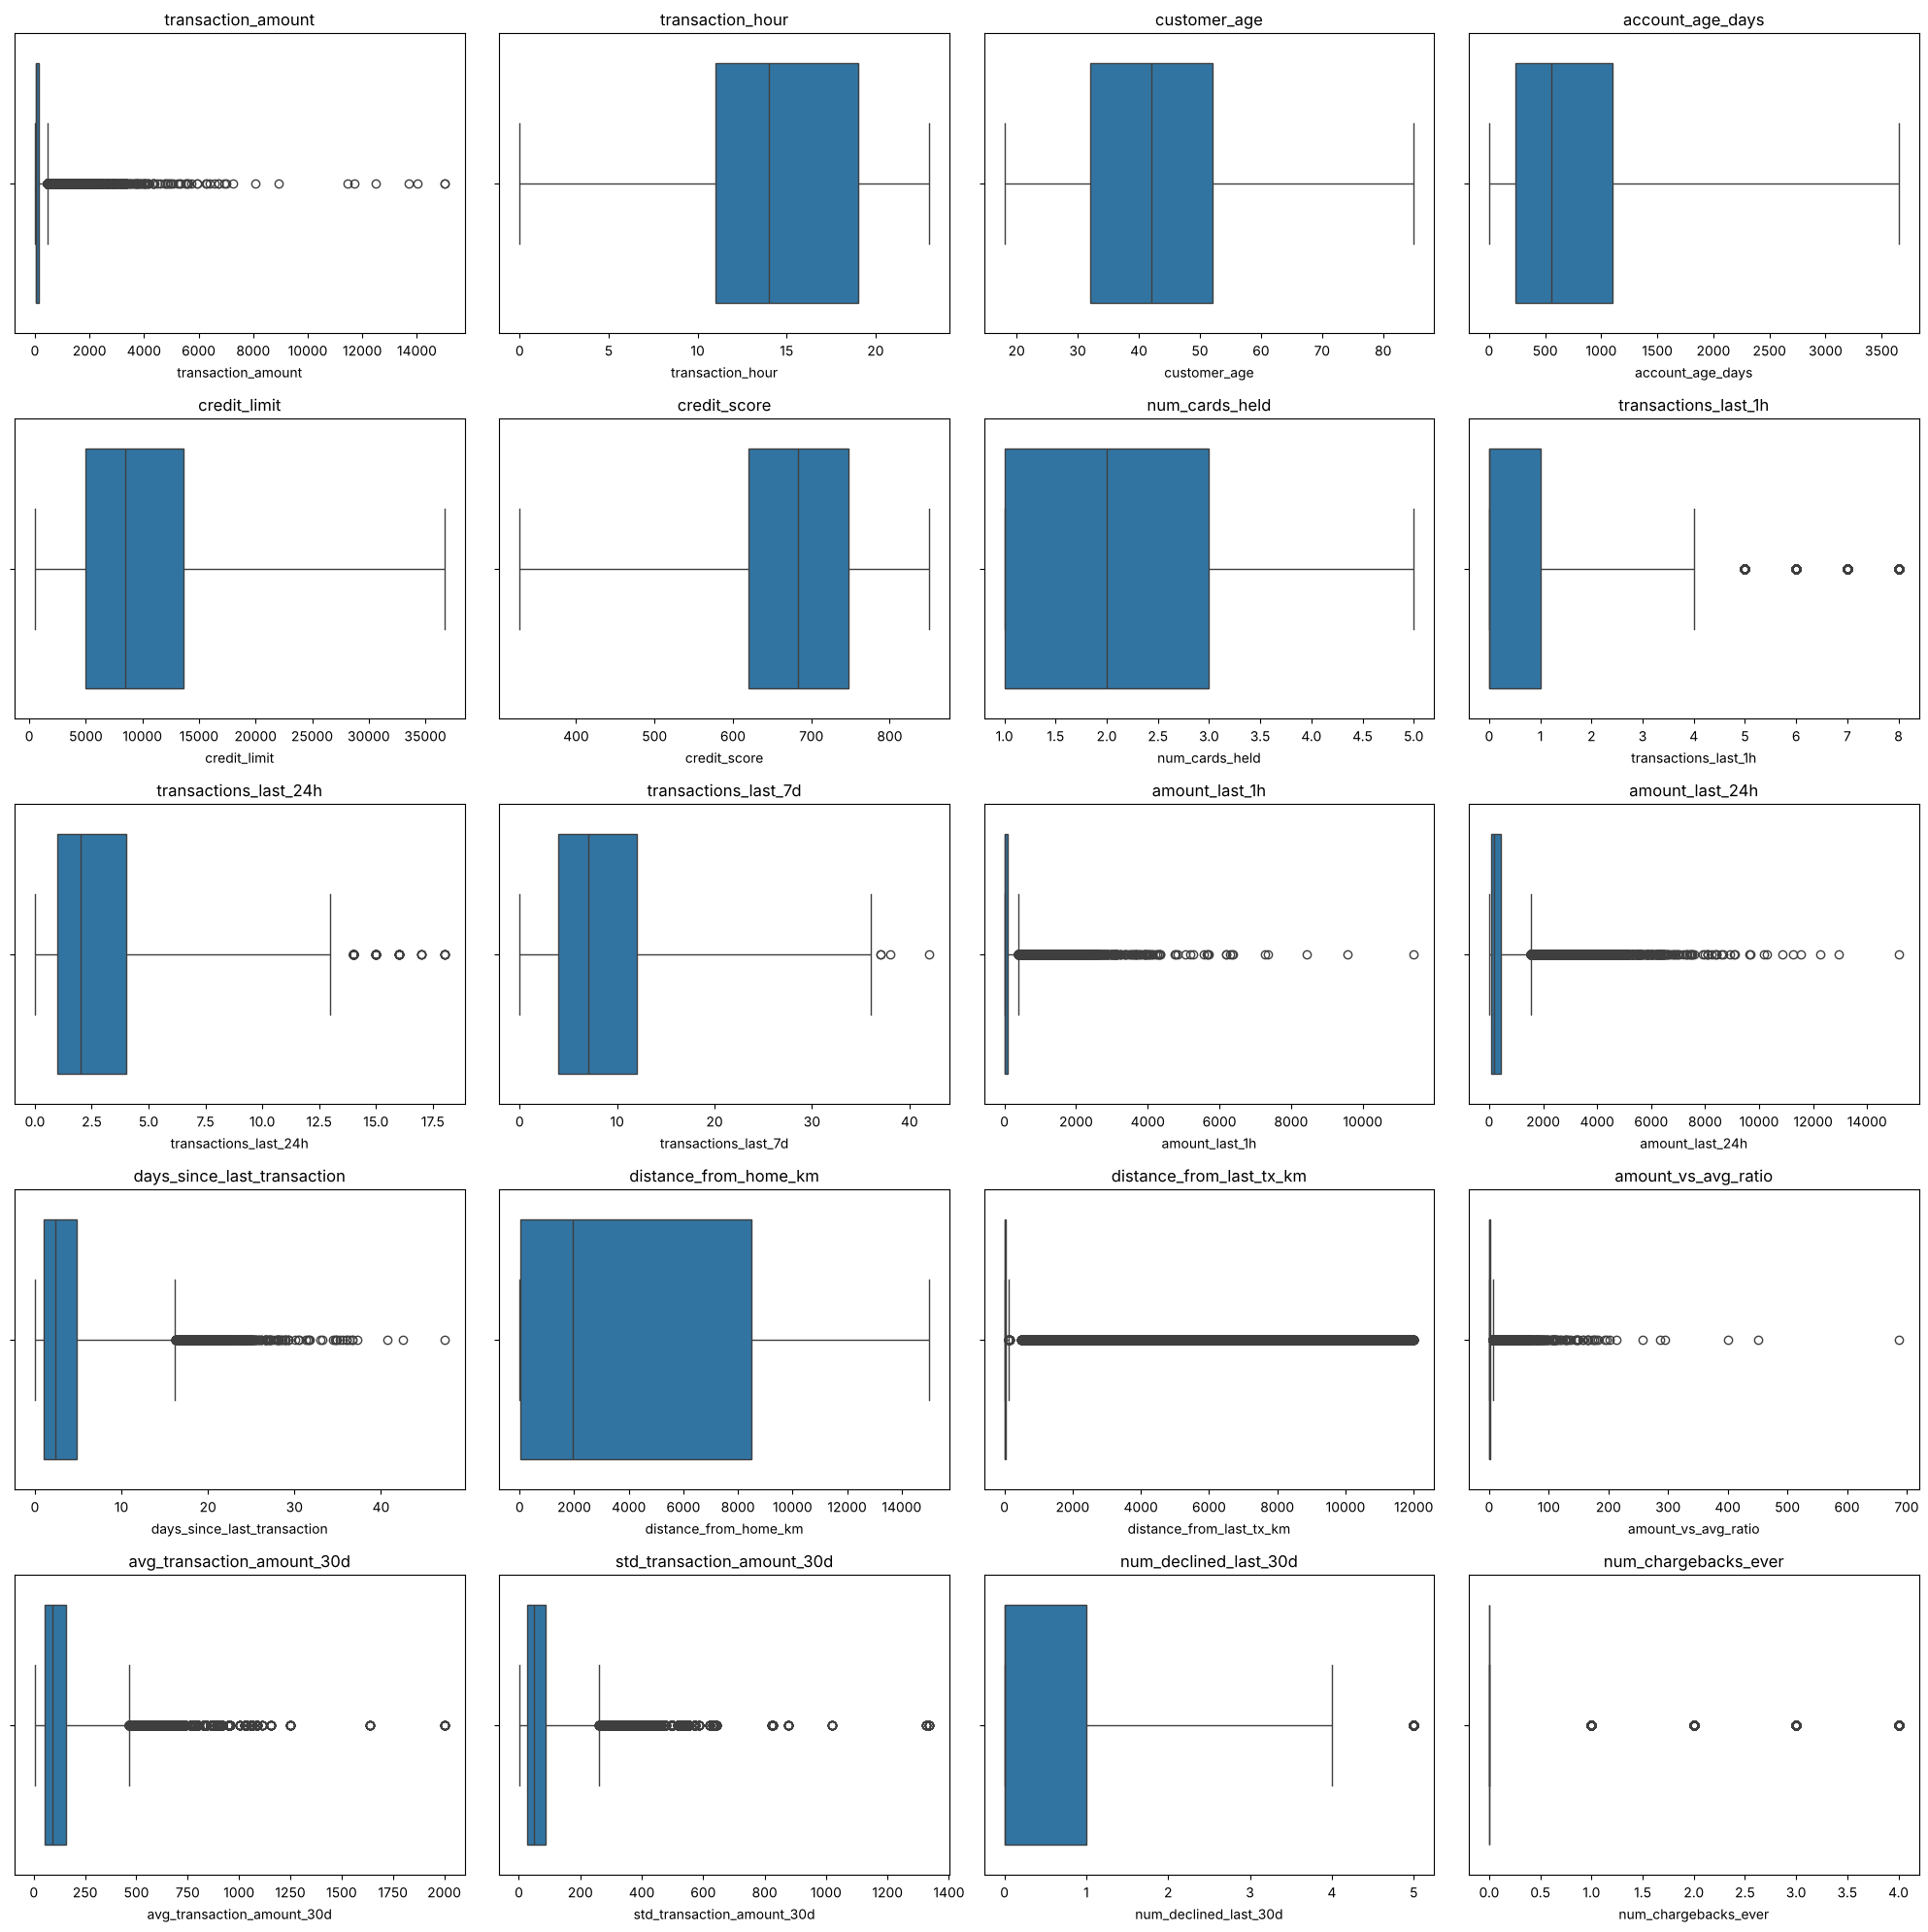

In [7]:
# Ambil kolom numerik, buang kolom biner (0/1), target, dan kolom kerugian fraud
num_cols = df.select_dtypes(include='number').columns
num_cols = [c for c in num_cols if df[c].nunique() > 2 and c not in ['fraud_amount_lost', 'is_fraud']]

# Hitung outlier dengan metode IQR (batas 3,0 x IQR)
hasil = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 3.0 * iqr, q3 + 3.0 * iqr
    if df[col].min() >= 0:                      # kolom yang tidak mungkin negatif
        batas_bawah = max(batas_bawah, 0)
    if iqr == 0:                                # IQR = 0 -> metode IQR tidak berlaku
        n_out, catatan = np.nan, 'IQR = 0, metode IQR tidak berlaku'
    else:
        n_out = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
        catatan = ''
    hasil.append([col, df[col].min(), df[col].max(), q1, q3, iqr, batas_bawah, batas_atas,
                  n_out, n_out / len(df) * 100, catatan])

outlier_df = pd.DataFrame(hasil, columns=['kolom', 'min', 'max', 'Q1', 'Q3', 'IQR', 'batas_bawah',
                                          'batas_atas', 'jumlah_outlier', 'persen_outlier', 'catatan'])
display(outlier_df.sort_values('persen_outlier', ascending=False).round(2))

# Cek nilai yang tidak masuk akal secara kontekstual
cek = {
    'customer_age < 18 atau > 100': ((df['customer_age'] < 18) | (df['customer_age'] > 100)).sum(),
    'credit_score di luar 300-850': ((df['credit_score'] < 300) | (df['credit_score'] > 850)).sum(),
    'transaction_hour di luar 0-23': (~df['transaction_hour'].between(0, 23)).sum(),
    'nilai negatif di kolom numerik': (df[num_cols] < 0).sum().sum(),
}
display(pd.Series(cek, name='jumlah baris').to_frame())

# Visualisasi boxplot tiap kolom
n = len(num_cols)
fig, axes = plt.subplots((n + 3) // 4, 4, figsize=(20, 4 * ((n + 3) // 4)))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], ax=ax, whis=3.0)     # whisker disamakan dengan batas 3,0 x IQR
    ax.set_title(col)
for ax in axes.flat[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

Berdasarkan penilaian outlier dan cek kontekstual, **tidak ada nilai yang janggal** (tidak ada usia, jarak, atau nominal negatif, dan credit score serta jam transaksi berada di rentang yang wajar). Nilai ekstrem yang ada (misalnya nominal transaksi besar atau jarak jauh) justru bisa menjadi sinyal fraud, jadi **tidak dibuang**. Kemiringan distribusinya ditangani dengan transformasi `log1p` saat preprocessing.

## 2.2 Membagi data latih dan data uji

**[PERBAIKAN]** Pada versi lama, uji statistik dijalankan pada **seluruh data (termasuk data uji)**, lalu hasilnya dipakai untuk memilih fitur skenario "Sedang-Lemah". Ini adalah *data leakage* ringan, karena informasi dari data uji ikut menentukan fitur. Sekarang data dibagi **lebih dulu**, dan uji statistik hanya memakai data latih.

Pembagian tetap sama seperti versi lama (80:20, stratified, `random_state=42`), jadi indeks data latih dan uji identik dengan notebook sebelumnya.

In [8]:
target = 'is_fraud'
y = df[target]
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
train_df = df.loc[idx_train]

print(f"Data latih: {len(idx_train):,} baris, fraud {y[idx_train].mean():.2%}")
print(f"Data uji  : {len(idx_test):,} baris, fraud {y[idx_test].mean():.2%}")

Data latih: 80,000 baris, fraud 2.05%
Data uji  : 20,000 baris, fraud 2.05%


## 2.3 Melakukan uji statistik untuk setiap kolom

**[PERBAIKAN]**
1. Uji dijalankan pada **data latih saja** (lihat 2.2).
2. `chi2_contingency` secara default memakai **koreksi Yates** untuk tabel 2x2 (kolom biner). Koreksi ini membuat nilai Chi-square, dan karena itu Cramér's V, sedikit lebih kecil dari seharusnya. Untuk effect size, Cramér's V dihitung dengan `correction=False`.
3. Ada 35 uji sekaligus, sehingga peluang "signifikan karena kebetulan" membesar. Ditambahkan kolom **signifikan setelah koreksi Bonferroni** (alpha = 0,05 / jumlah uji).

Rumus rank-biserial untuk Mann-Whitney U sudah benar dan tidak diubah. Karena targetnya biner, Cramér's V sama dengan phi, sehingga batas kekuatan 0,1 / 0,3 / 0,5 tetap tepat.

In [9]:
drop = ['transaction_id', 'customer_id', 'card_id', 'merchant_id',
        'transaction_datetime', 'fraud_type', 'fraud_amount_lost', target]
fitur = [c for c in df.columns if c not in drop]

# Numerik = lebih dari 2 nilai unik; sisanya (kategori & biner) diuji Chi-square
num_cols = [c for c in fitur if pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 2]
cat_cols = [c for c in fitur if c not in num_cols]

fraud = train_df[train_df[target] == 1]
non_fraud = train_df[train_df[target] == 0]
hasil = []

# Numerik: Mann-Whitney U (data tidak normal), effect size = rank-biserial
for c in num_cols:
    u, p = stats.mannwhitneyu(fraud[c], non_fraud[c])
    r = abs(1 - 2 * u / (len(fraud) * len(non_fraud)))
    hasil.append([c, 'Mann-Whitney U', p, r])

# Kategorikal: Chi-square tanpa koreksi Yates, effect size = Cramér's V
for c in cat_cols:
    tabel = pd.crosstab(train_df[c], train_df[target])
    chi2, p, _, _ = stats.chi2_contingency(tabel, correction=False)
    v = np.sqrt(chi2 / (tabel.values.sum() * (min(tabel.shape) - 1)))
    hasil.append([c, 'Chi-square', p, v])

hasil_uji = pd.DataFrame(hasil, columns=['kolom', 'uji', 'p_value', 'effect_size'])
alpha_bonf = 0.05 / len(hasil_uji)
hasil_uji['signifikan'] = hasil_uji['p_value'] < 0.05
hasil_uji['signifikan_bonferroni'] = hasil_uji['p_value'] < alpha_bonf
hasil_uji['kekuatan'] = pd.cut(hasil_uji['effect_size'], [-1, 0.1, 0.3, 0.5, np.inf],
                               labels=['sangat lemah', 'lemah', 'sedang', 'kuat'])
display(hasil_uji.sort_values('effect_size', ascending=False)
        .style.format({'p_value': '{:.4f}', 'effect_size': '{:.4f}'}))

print(f"Alpha Bonferroni = 0,05 / {len(hasil_uji)} = {alpha_bonf:.5f}")
print("Signifikan (Bonferroni):", hasil_uji.loc[hasil_uji['signifikan_bonferroni'], 'kolom'].tolist())
print("Tidak signifikan       :", hasil_uji.loc[~hasil_uji['signifikan_bonferroni'], 'kolom'].tolist())

,kolom,uji,p_value,effect_size,signifikan,signifikan_bonferroni,kekuatan
13,distance_from_home_km,Mann-Whitney U,0.0000,0.3725,True,True,sedang
3,account_age_days,Mann-Whitney U,0.0000,0.1800,True,True,lemah
21,merchant_country,Chi-square,0.0000,0.1675,True,True,lemah
7,transactions_last_1h,Mann-Whitney U,0.0000,0.1479,True,True,lemah
27,high_risk_country,Chi-square,0.0000,0.1462,True,True,lemah
10,amount_last_1h,Mann-Whitney U,0.0000,0.1262,True,True,lemah
19,num_chargebacks_ever,Mann-Whitney U,0.0000,0.1173,True,True,lemah
8,transactions_last_24h,Mann-Whitney U,0.0000,0.1164,True,True,lemah
26,international_transaction,Chi-square,0.0000,0.1076,True,True,lemah
14,distance_from_last_tx_km,Mann-Whitney U,0.0000,0.0919,True,True,sangat lemah


Alpha Bonferroni = 0,05 / 35 = 0.00143
Signifikan (Bonferroni): ['transaction_amount', 'transaction_hour', 'account_age_days', 'credit_score', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'num_declined_last_30d', 'num_chargebacks_ever', 'merchant_category', 'merchant_country', 'card_present', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser']
Tidak signifikan       : ['customer_age', 'credit_limit', 'num_cards_held', 'days_since_last_transaction', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'transaction_day_of_week', 'customer_gender', 'customer_state', 'is_weekend', 'email_domain']


Hampir semua fitur berbeda signifikan antara fraud dan non-fraud, tetapi **effect size-nya kecil** (tertinggi `distance_from_home_km` sekitar 0,37, sisanya di bawah 0,2). Artinya tidak ada satu fitur pun yang bisa memisahkan fraud sendirian. Sinyalnya lemah dan tersebar, sehingga model yang bisa menangkap **kombinasi dan interaksi** antar fitur (seperti Gradient Boosting) berpotensi lebih baik daripada model linear.

# 3 MACHINE LEARNING MAKING

## Analisis Biaya Kesalahan Prediksi dan Pemilihan Metrik

### Konteks Bisnis
Sistem yang dibangun adalah **Early Warning System** untuk transaksi mencurigakan. Transaksi yang diprediksi `is_fraud = 1` akan **ditunda dengan SLA maksimal 1x24 jam**, lalu tim **Fraud Authorization** melakukan konfirmasi ke Cardholder:
- Jika **terbukti fraud**: transaksi dibatalkan.
- Jika **legit**: transaksi dilanjutkan.

### 1. Kerugian False Negative (fraud lolos, tidak ditunda)
Transaksi fraud yang tidak terdeteksi langsung menjadi kerugian. Berdasarkan kolom `fraud_amount_lost` pada 2.055 transaksi fraud:

| Ukuran | Nilai |
|---|---|
| Rata-rata kerugian per kasus | **$136,18** |
| Median | $50,09 |
| Maksimum | $4.482,16 |
| Total kerugian di dataset | **$279.842** |

Rata-rata kerugian per jenis fraud:

| Jenis Fraud | Jumlah Kasus | Rata-rata Kerugian |
|---|---|---|
| Card-Not-Present | 1.054 | $142,79 |
| Account-Takeover | 447 | $139,36 |
| Card-Present | 245 | $131,36 |
| Synthetic-Identity | 309 | $112,82 |

### 2. Kerugian False Positive (transaksi legit ikut ditunda)
Transaksi legit hanya ditunda lalu dilanjutkan, jadi nilai transaksinya tidak hilang. Kerugiannya berupa:
- **Biaya operasional** tim Fraud Authorization untuk konfirmasi ke Cardholder (waktu analis, telepon/SMS).
- **Pendapatan interchange yang hilang** jika nasabah batal atau pindah kartu: sekitar 2% × rata-rata transaksi legit ($125,97) ≈ **$2,52**.
- **Risiko nasabah kecewa atau churn**.

Estimasi dengan asumsi biaya konfirmasi $5 per kasus:

$$\text{Biaya FP} \approx \$5 + \$2{,}52 \approx \textbf{\$7,50 per kasus}$$

> **Catatan:** angka $5 adalah asumsi dan perlu diganti dengan biaya riil dari tim Fraud Authorization.

**Perbandingan:** 1 False Negative ($136) ≈ **18 False Positive** ($7,50).

### 3. Pemilihan Metrik
Karena FN jauh lebih mahal daripada FP, **Recall** menjadi prioritas utama supaya sebanyak mungkin fraud tertangkap. Namun **Precision** tetap perlu dijaga, karena kapasitas tim Fraud Authorization terbatas untuk memenuhi SLA 1x24 jam.

| Metrik | Kesesuaian | Alasan |
|---|---|---|
| Accuracy | ❌ | Fraud hanya 2,06%. Menebak semua "legit" sudah memberi akurasi 97,9% |
| Precision | ⚠️ | Penting untuk beban kerja tim, tapi bukan metrik utama |
| Recall | ✅ | Paling penting karena FN sangat mahal |
| F1-Score | ⚠️ | Menganggap FP dan FN sama mahalnya, padahal tidak |
| **F2-Score** | ✅✅ | **Direkomendasikan**: memberi bobot Recall lebih besar daripada Precision |

### Rekomendasi
1. Gunakan **F2-Score** sebagai metrik utama evaluasi model.
2. Tentukan threshold berdasarkan **total biaya terendah**:
   $$\text{Total Biaya} = (FN \times \$136) + (FP \times \$7{,}50)$$
3. Tetapkan **batas minimum Precision** sesuai kapasitas harian tim Fraud Authorization.

**Verifikasi angka biaya** dari data (supaya angka di atas tidak diketik manual):

In [10]:
f = df[df[target] == 1]
BIAYA_FN = round(f['fraud_amount_lost'].mean(), 2)
rata_legit = df.loc[df[target] == 0, 'transaction_amount'].mean()
BIAYA_KONFIRMASI = 5.00                      # asumsi, ganti dengan biaya riil tim
INTERCHANGE = 0.02 * rata_legit
BIAYA_FP = 7.50                              # dibulatkan dari 5 + 2,52

print(f"Jumlah fraud                 : {len(f):,} ({len(f)/len(df):.2%})")
print(f"Rata-rata kerugian per fraud : ${BIAYA_FN:,.2f}")
print(f"Median / maksimum            : ${f['fraud_amount_lost'].median():,.2f} / ${f['fraud_amount_lost'].max():,.2f}")
print(f"Total kerugian               : ${f['fraud_amount_lost'].sum():,.2f}")
print(f"Rata-rata transaksi legit    : ${rata_legit:,.2f} -> interchange 2% = ${INTERCHANGE:,.2f}")
print(f"Biaya FP                     : ${BIAYA_KONFIRMASI:,.2f} + ${INTERCHANGE:,.2f} = ${BIAYA_KONFIRMASI+INTERCHANGE:,.2f} (dipakai ${BIAYA_FP:,.2f})")
print(f"1 FN setara                  : {BIAYA_FN / BIAYA_FP:,.2f} FP")
display(f.groupby('fraud_type')['fraud_amount_lost'].agg(['count', 'mean']).sort_values('count', ascending=False))

Jumlah fraud                 : 2,055 (2.05%)
Rata-rata kerugian per fraud : $136.18
Median / maksimum            : $50.09 / $4,482.16
Total kerugian               : $279,842.20
Rata-rata transaksi legit    : $125.97 -> interchange 2% = $2.52
Biaya FP                     : $5.00 + $2.52 = $7.52 (dipakai $7.50)
1 FN setara                  : 18.16 FP


,count,mean
fraud_type,,
Card-Not-Present,1054,142.79
Account-Takeover,447,139.36
Synthetic-Identity,309,112.82
Card-Present,245,131.36


Semua angka di tabel biaya **sudah benar** setelah diverifikasi dari data. Satu catatan: angka $7,50 menganggap **setiap** FP kehilangan interchange 2%, padahal di teks disebutkan kerugian itu hanya terjadi *jika* nasabah batal. Jadi $7,50 adalah perkiraan atas (konservatif). Ini tidak mengubah kesimpulan, karena FN tetap jauh lebih mahal.

## 3.1 Preprocessing

**[PERBAIKAN]**
- Fungsi `buat_preprocessor` versi pertama (yang memakai `num`/`cat`) tidak pernah dipakai karena ditimpa oleh versi di sel berikutnya. Fungsi itu dihapus supaya tidak membingungkan.
- Pada versi lama, `preprocessor.fit_transform` dijalankan pada **seluruh data** (termasuk data uji) untuk mengecek bentuk data. Sekarang hanya di-*fit* pada data latih. Ini juga menghilangkan kolom target dari input.
- Definisi daftar kolom sebelumnya ditulis dua kali (sel cek dan sel pipeline). Sekarang cukup sekali.
- `OneHotEncoder(sparse_output=False)` supaya hasil transformasi bisa langsung dipakai untuk SHAP.

In [11]:
set_config(display='diagram')

kol_biner = ['card_present', 'international_transaction', 'high_risk_country',
             'used_chip', 'used_pin', 'is_weekend']
kol_onehot = ['merchant_category', 'merchant_country', 'transaction_day_of_week',
              'customer_gender', 'customer_state', 'transaction_channel',
              'device_type', 'email_domain']          # browser ditangani terpisah
kol_log = ['transaction_amount', 'amount_vs_avg_ratio', 'amount_last_1h',
           'amount_last_24h', 'avg_transaction_amount_30d', 'std_transaction_amount_30d',
           'distance_from_last_tx_km', 'transactions_last_1h', 'num_declined_last_30d',
           'num_chargebacks_ever', 'days_since_last_transaction']
kol_scale = ['account_age_days', 'transactions_last_24h', 'transactions_last_7d',
             'credit_limit', 'customer_age', 'credit_score', 'transaction_hour',
             'num_cards_held', 'distance_from_home_km']
fitur_semua = kol_biner + ['browser'] + kol_onehot + kol_log + kol_scale

def buat_preprocessor(fitur):
    t = []
    b = [c for c in kol_biner if c in fitur]
    if b: t.append(('biner', 'passthrough', b))
    if 'browser' in fitur:
        t.append(('browser', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='offline')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), ['browser']))
    o = [c for c in kol_onehot if c in fitur]
    if o: t.append(('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), o))
    l = [c for c in kol_log if c in fitur]
    if l: t.append(('log', Pipeline([
        ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', StandardScaler())]), l))
    s = [c for c in kol_scale if c in fitur]
    if s: t.append(('scale', StandardScaler(), s))
    return ColumnTransformer(t)

X_train, y_train = df.loc[idx_train, fitur_semua], y[idx_train]
X_test, y_test = df.loc[idx_test, fitur_semua], y[idx_test]

# Cek hasil transformasi (fit di data latih saja)
X_proc = buat_preprocessor(fitur_semua).fit_transform(X_train)
print("Bentuk data latih setelah preprocessing:", X_proc.shape)

Pipeline([('prep', buat_preprocessor(fitur_semua)),
          ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])

Bentuk data latih setelah preprocessing: (80000, 131)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('biner', ...), ('browser', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If 

## 3.2 Baseline (threshold 0,5): Semua fitur vs Sedang-Lemah

Ini adalah perbandingan dari notebook lama, dijalankan ulang dengan fitur "Sedang-Lemah" dari uji statistik di data latih. Ditambahkan **ROC-AUC** dan **PR-AUC** karena keduanya tidak bergantung pada threshold.

Catatan: pada threshold 0,5, model tanpa penyeimbang kelas (KNN) atau yang probabilitasnya jarang melewati 0,5 (Random Forest) akan terlihat "tidak menangkap fraud sama sekali". Ini lebih karena **threshold**, bukan karena model tidak punya sinyal. Lihat ROC-AUC Random Forest yang sebenarnya bagus. Karena itu perbandingan yang adil ada di bagian 3.3.

In [12]:
fitur_sedang_lemah = hasil_uji.loc[hasil_uji['kekuatan'].isin(['sedang', 'lemah']), 'kolom'].tolist()
print("Fitur Sedang-Lemah:", fitur_sedang_lemah)

models_baseline = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': lambda: DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'KNN': lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                                    n_jobs=-1, random_state=RANDOM_STATE),
}

hasil_model = []
for nama_skenario, fitur in {'Semua fitur': fitur_semua, 'Sedang-Lemah': fitur_sedang_lemah}.items():
    for nama_model, buat_model in models_baseline.items():
        pipe = Pipeline([('prep', buat_preprocessor(fitur)), ('model', buat_model())])
        pipe.fit(df.loc[idx_train, fitur], y[idx_train])
        proba = pipe.predict_proba(df.loc[idx_test, fitur])[:, 1]
        y_pred = (proba >= 0.5).astype(int)
        hasil_model.append({
            'Skenario': nama_skenario, 'Model': nama_model,
            'Precision': precision_score(y[idx_test], y_pred, zero_division=0),
            'Recall': recall_score(y[idx_test], y_pred),
            'F2-Score': fbeta_score(y[idx_test], y_pred, beta=2),
            'ROC-AUC': roc_auc_score(y[idx_test], proba),
            'PR-AUC': average_precision_score(y[idx_test], proba),
        })

hasil_model = pd.DataFrame(hasil_model).sort_values('F2-Score', ascending=False)
display(hasil_model.round(4))
display(hasil_model.pivot(index='Model', columns='Skenario', values='F2-Score').round(4))

Fitur Sedang-Lemah: ['account_age_days', 'transactions_last_1h', 'transactions_last_24h', 'amount_last_1h', 'distance_from_home_km', 'num_chargebacks_ever', 'merchant_country', 'international_transaction', 'high_risk_country']


,Skenario,Model,Precision,Recall,F2-Score,ROC-AUC,PR-AUC
0,Semua fitur,Logistic Regression,0.06,0.76,0.22,0.83,0.12
4,Sedang-Lemah,Logistic Regression,0.05,0.76,0.19,0.80,0.10
5,Sedang-Lemah,Decision Tree,0.11,0.11,0.11,0.55,0.03
1,Semua fitur,Decision Tree,0.07,0.08,0.08,0.53,0.02
7,Sedang-Lemah,Random Forest,0.17,0.06,0.07,0.75,0.07
6,Sedang-Lemah,KNN,0.17,0.01,0.01,0.57,0.03
3,Semua fitur,Random Forest,0.20,0.00,0.01,0.82,0.12
2,Semua fitur,KNN,0.00,0.00,0.00,0.57,0.03


Skenario,Sedang-Lemah,Semua fitur
Model,,
Decision Tree,0.11,0.08
KNN,0.01,0.00
Logistic Regression,0.19,0.22
Random Forest,0.07,0.01


Skenario **Semua fitur** lebih baik untuk model terbaik baseline (Logistic Regression), jadi perbandingan model berikutnya memakai semua fitur. Fitur yang lemah tetap bisa berguna jika dikombinasikan dengan fitur lain.

## 3.3 Perbandingan model yang adil (tuning + threshold berbasis biaya)

Supaya adil, **semua model** diperlakukan sama:
1. **Data sama**: data latih dan data uji yang sama, fitur yang sama (semua fitur), preprocessing yang sama.
2. **Tuning hyperparameter** dengan cross-validation 3-fold di data latih, metrik **PR-AUC** (cocok untuk data sangat tidak seimbang). Penanganan imbalance (`class_weight` / `scale_pos_weight`) ikut di-tuning.
3. **Threshold** tiap model dipilih dari **prediksi cross-validation 5-fold di data latih** (out-of-fold), yaitu threshold dengan **total biaya terendah**:
$$\text{Total Biaya} = FN \times \$136{,}18 + FP \times \$7{,}50$$
4. Model final dipilih dari **biaya cross-validation terendah**. Data uji hanya dipakai **sekali** di akhir untuk melaporkan hasil.

Model yang dibandingkan: Logistic Regression, Decision Tree, KNN, Random Forest, HistGradientBoosting, LightGBM, dan XGBoost.

*Catatan waktu: sel ini memerlukan sekitar 10-15 menit di CPU 4 core.*

In [13]:
cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
spw = (y_train == 0).sum() / (y_train == 1).sum()      # rasio non-fraud : fraud (sekitar 47,6)

def hitung_biaya(y_true, proba, thresholds=np.round(np.arange(0.005, 1.0, 0.005), 3)):
    """Total biaya (FN x BIAYA_FN + FP x BIAYA_FP) untuk setiap threshold."""
    y_true = np.asarray(y_true)
    rows = []
    for t in thresholds:
        pred = proba >= t
        tp = int((pred & (y_true == 1)).sum()); fp = int((pred & (y_true == 0)).sum())
        fn = int((~pred & (y_true == 1)).sum())
        rows.append({'threshold': t, 'TP': tp, 'FP': fp, 'FN': fn,
                     'Precision': tp / (tp + fp) if tp + fp else 0, 'Recall': tp / (tp + fn),
                     'Total Biaya': fn * BIAYA_FN + fp * BIAYA_FP})
    out = pd.DataFrame(rows)
    p, r = out['Precision'], out['Recall']
    out['F2-Score'] = np.where(p + r > 0, 5 * p * r / (4 * p + r), 0)
    return out

kandidat = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, class_weight='balanced'),
        {'model__C': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}),
    'Decision Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'model__max_depth': [3, 4, 5, 6, 8, 10], 'model__min_samples_leaf': [20, 50, 100, 200, 500]}),
    'KNN': (
        KNeighborsClassifier(n_jobs=-1),
        {'model__n_neighbors': [25, 51, 101], 'model__weights': ['uniform', 'distance']}),
    'Random Forest': (
        RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1,
                               random_state=RANDOM_STATE),
        {'model__max_depth': [8, 12, 16, None], 'model__min_samples_leaf': [10, 20, 50],
         'model__max_features': ['sqrt', 0.3]}),
    'HistGradientBoosting': (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        {'model__learning_rate': [0.03, 0.05, 0.1], 'model__max_iter': [200, 400],
         'model__max_leaf_nodes': [7, 15, 31], 'model__min_samples_leaf': [50, 100, 200],
         'model__l2_regularization': [0, 1, 5], 'model__class_weight': [None, 'balanced']}),
    'LightGBM': (
        LGBMClassifier(subsample_freq=1, importance_type='gain', verbose=-1,
                       random_state=RANDOM_STATE, n_jobs=4),
        {'model__n_estimators': [300, 500, 800], 'model__learning_rate': [0.02, 0.03, 0.05],
         'model__num_leaves': [7, 15, 31], 'model__min_child_samples': [50, 100, 200],
         'model__subsample': [0.7, 0.8, 1.0], 'model__colsample_bytree': [0.5, 0.7, 0.9],
         'model__reg_lambda': [0, 1, 5, 10], 'model__scale_pos_weight': [1, 5, spw]}),
    'XGBoost': (
        XGBClassifier(tree_method='hist', eval_metric='aucpr', random_state=RANDOM_STATE, n_jobs=4),
        {'model__n_estimators': [300, 500, 800], 'model__learning_rate': [0.02, 0.03, 0.05],
         'model__max_depth': [3, 4, 5, 6], 'model__min_child_weight': [1, 5, 10, 20],
         'model__subsample': [0.7, 0.8, 1.0], 'model__colsample_bytree': [0.5, 0.7, 0.9],
         'model__reg_lambda': [1, 5, 10], 'model__scale_pos_weight': [1, 5, spw]}),
}
N_ITER = {'Decision Tree': 10, 'Random Forest': 6, 'HistGradientBoosting': 12, 'LightGBM': 15, 'XGBoost': 15}

hasil_cv, model_terbaik, oof_semua, kurva_biaya = [], {}, {}, {}
for nama, (est, grid) in kandidat.items():
    t0 = time.time()
    pipe = Pipeline([('prep', buat_preprocessor(fitur_semua)), ('model', est)])
    n_kombinasi = np.prod([len(v) for v in grid.values()])
    if n_kombinasi <= 12:
        search = GridSearchCV(pipe, grid, scoring='average_precision', cv=cv_tune, n_jobs=1)
    else:
        search = RandomizedSearchCV(pipe, grid, n_iter=N_ITER[nama], scoring='average_precision',
                                    cv=cv_tune, n_jobs=1, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    best = search.best_estimator_

    # Prediksi out-of-fold 5-fold di data latih -> dasar pemilihan threshold
    oof = cross_val_predict(best, X_train, y_train, cv=cv_oof, method='predict_proba')[:, 1]
    kurva = hitung_biaya(y_train, oof)
    terbaik = kurva.loc[kurva['Total Biaya'].idxmin()]

    model_terbaik[nama], oof_semua[nama], kurva_biaya[nama] = best, oof, kurva
    hasil_cv.append({
        'Model': nama,
        'CV ROC-AUC': roc_auc_score(y_train, oof), 'CV PR-AUC': average_precision_score(y_train, oof),
        'Threshold': terbaik['threshold'], 'CV Precision': terbaik['Precision'],
        'CV Recall': terbaik['Recall'], 'CV F2': terbaik['F2-Score'], 'CV Total Biaya': terbaik['Total Biaya'],
        'Param terbaik': {k.replace('model__', ''): (round(v, 3) if isinstance(v, float) else v)
                          for k, v in search.best_params_.items()},
    })
    print(f"{nama:22s} selesai dalam {time.time() - t0:5.0f} detik")

hasil_cv = pd.DataFrame(hasil_cv).sort_values('CV Total Biaya').reset_index(drop=True)
biaya_tanpa_model_cv = y_train.sum() * BIAYA_FN
hasil_cv['Penghematan vs tanpa model'] = 1 - hasil_cv['CV Total Biaya'] / biaya_tanpa_model_cv
display(hasil_cv.drop(columns='Param terbaik').style.format({
    'CV ROC-AUC': '{:.4f}', 'CV PR-AUC': '{:.4f}', 'Threshold': '{:.3f}', 'CV Precision': '{:.4f}',
    'CV Recall': '{:.4f}', 'CV F2': '{:.4f}', 'CV Total Biaya': '${:,.2f}', 'Penghematan vs tanpa model': '{:.2%}'}))
for _, r in hasil_cv.iterrows():
    print(f"{r['Model']:22s} {r['Param terbaik']}")

Logistic Regression    selesai dalam    24 detik


Decision Tree          selesai dalam    29 detik


KNN                    selesai dalam    57 detik


Random Forest          selesai dalam   213 detik


HistGradientBoosting   selesai dalam   105 detik


LightGBM               selesai dalam    70 detik


XGBoost                selesai dalam    98 detik


,Model,CV ROC-AUC,CV PR-AUC,Threshold,CV Precision,CV Recall,CV F2,CV Total Biaya,Penghematan vs tanpa model
0,LightGBM,0.8507,0.1732,0.210,0.1139,0.5505,0.3116,"$153,459.52",31.45%
1,XGBoost,0.8484,0.1683,0.670,0.1102,0.5590,0.3081,"$154,388.00",31.04%
2,HistGradientBoosting,0.8481,0.1640,0.070,0.1374,0.4592,0.3128,"$156,599.02",30.05%
3,Random Forest,0.8332,0.1385,0.605,0.1123,0.4909,0.2932,"$161,810.16",27.72%
4,Logistic Regression,0.8356,0.1417,0.700,0.1064,0.4976,0.2867,"$164,017.18",26.74%
5,Decision Tree,0.8080,0.1110,0.750,0.1096,0.4647,0.2819,"$166,405.90",25.67%
6,KNN,0.7633,0.0777,0.040,0.0840,0.3704,0.2203,"$190,746.30",14.80%


LightGBM               {'subsample': 0.8, 'scale_pos_weight': 5, 'reg_lambda': 1, 'num_leaves': 7, 'n_estimators': 500, 'min_child_samples': 200, 'learning_rate': 0.02, 'colsample_bytree': 0.5}
XGBoost                {'subsample': 0.8, 'scale_pos_weight': np.float64(47.662), 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
HistGradientBoosting   {'min_samples_leaf': 50, 'max_leaf_nodes': 7, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 5, 'class_weight': None}
Random Forest          {'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 12}
Logistic Regression    {'C': 0.003}
Decision Tree          {'min_samples_leaf': 100, 'max_depth': 6}
KNN                    {'n_neighbors': 101, 'weights': 'distance'}


### Evaluasi di data uji (dipakai sekali, setelah semua model dan threshold terkunci)

Setiap model dilatih ulang di seluruh data latih (sudah dilakukan oleh `search.best_estimator_`), lalu diuji dengan threshold yang dipilih dari cross-validation. `Biaya riil` memakai `fraud_amount_lost` asli dari setiap fraud yang lolos, bukan rata-rata.

Biaya tanpa model di data uji (semua fraud lolos): $55,969.98 (riil $64,497.29)


,Model,Threshold,Precision,Recall,F2-Score,ROC-AUC,PR-AUC,TP,FP,FN,Total Biaya,Biaya riil,Alert per hari,Penghematan
0,LightGBM,0.210,0.1146,0.5499,0.3125,0.8568,0.1605,226,1746,185,"$38,288.30","$35,715.18",27.0,31.59%
1,XGBoost,0.670,0.1081,0.5547,0.3037,0.8548,0.1622,228,1882,183,"$39,035.94","$34,936.88",28.9,30.26%
2,HistGradientBoosting,0.070,0.1330,0.4550,0.3066,0.8540,0.1640,187,1219,224,"$39,646.82","$36,814.50",19.3,29.16%
3,Random Forest,0.605,0.1029,0.4720,0.2748,0.8373,0.1346,194,1692,217,"$42,241.06","$39,299.19",25.8,24.53%
4,Logistic Regression,0.700,0.1000,0.4672,0.2694,0.8383,0.1207,192,1728,219,"$42,783.42","$34,664.07",26.3,23.56%
5,Decision Tree,0.750,0.1026,0.4331,0.2634,0.8054,0.1114,178,1557,233,"$43,407.44","$42,166.60",23.8,22.45%
6,KNN,0.040,0.0781,0.3358,0.2023,0.7616,0.0762,138,1629,273,"$49,394.64","$45,187.84",24.2,11.75%


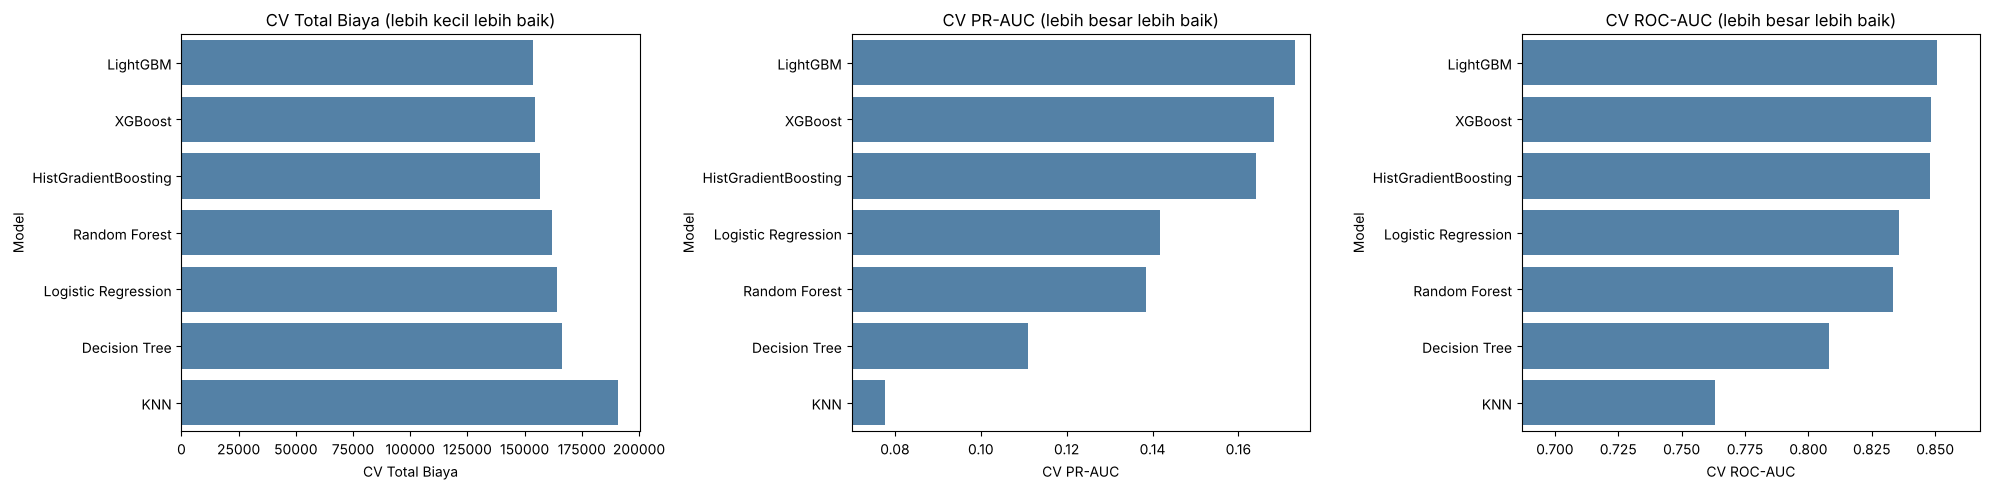

In [14]:
loss_test = df.loc[idx_test, 'fraud_amount_lost'].values
tx_per_hari = len(df) / 365                          # sekitar 274 transaksi per hari

def evaluasi(y_true, proba, t):
    y_true = np.asarray(y_true); pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'Threshold': t, 'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred), 'F2-Score': fbeta_score(y_true, pred, beta=2),
        'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
        'TP': tp, 'FP': fp, 'FN': fn,
        'Total Biaya': fn * BIAYA_FN + fp * BIAYA_FP,
        'Biaya riil': loss_test[(pred == 0) & (y_true == 1)].sum() + fp * BIAYA_FP,
        'Alert per hari': pred.mean() * tx_per_hari,
    }

proba_test, hasil_test = {}, []
for nama in hasil_cv['Model']:
    proba_test[nama] = model_terbaik[nama].predict_proba(X_test)[:, 1]
    t = hasil_cv.loc[hasil_cv['Model'] == nama, 'Threshold'].iloc[0]
    hasil_test.append({'Model': nama, **evaluasi(y_test, proba_test[nama], t)})

hasil_test = pd.DataFrame(hasil_test)
biaya_tanpa_model = y_test.sum() * BIAYA_FN
hasil_test['Penghematan'] = 1 - hasil_test['Total Biaya'] / biaya_tanpa_model
print(f"Biaya tanpa model di data uji (semua fraud lolos): ${biaya_tanpa_model:,.2f} "
      f"(riil ${loss_test.sum():,.2f})")
display(hasil_test.style.format({
    'Threshold': '{:.3f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F2-Score': '{:.4f}',
    'ROC-AUC': '{:.4f}', 'PR-AUC': '{:.4f}', 'Total Biaya': '${:,.2f}', 'Biaya riil': '${:,.2f}',
    'Alert per hari': '{:.1f}', 'Penghematan': '{:.2%}'}))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, kol in zip(axes, ['CV Total Biaya', 'CV PR-AUC', 'CV ROC-AUC']):
    d = hasil_cv.sort_values(kol, ascending=(kol == 'CV Total Biaya'))
    sns.barplot(data=d, y='Model', x=kol, ax=ax, color='steelblue')
    ax.set_title(kol + (' (lebih kecil lebih baik)' if 'Biaya' in kol else ' (lebih besar lebih baik)'))
    if 'Biaya' not in kol:
        ax.set_xlim(d[kol].min() * 0.9, d[kol].max() * 1.02)
plt.tight_layout(); plt.show()

## 3.4 Model final

Model final dipilih secara otomatis: **biaya cross-validation terendah** di data latih (tidak melihat data uji).

Model final : LightGBM
Threshold   : 0.210 (biaya CV terendah)
Parameter   : {'subsample': 0.8, 'scale_pos_weight': 5, 'reg_lambda': 1, 'num_leaves': 7, 'n_estimators': 500, 'min_child_samples': 200, 'learning_rate': 0.02, 'colsample_bytree': 0.5}


,Threshold,Precision,Recall,F2-Score,ROC-AUC,PR-AUC,TP,FP,FN,Total Biaya,Biaya riil,Alert per hari
LightGBM (final),0.210,0.1146,0.5499,0.3125,0.8568,0.1605,226,1746,185,"$38,288.30","$35,715.18",27.0
Logistic Regression (baseline tuned),0.700,0.1000,0.4672,0.2694,0.8383,0.1207,192,1728,219,"$42,783.42","$34,664.07",26.3


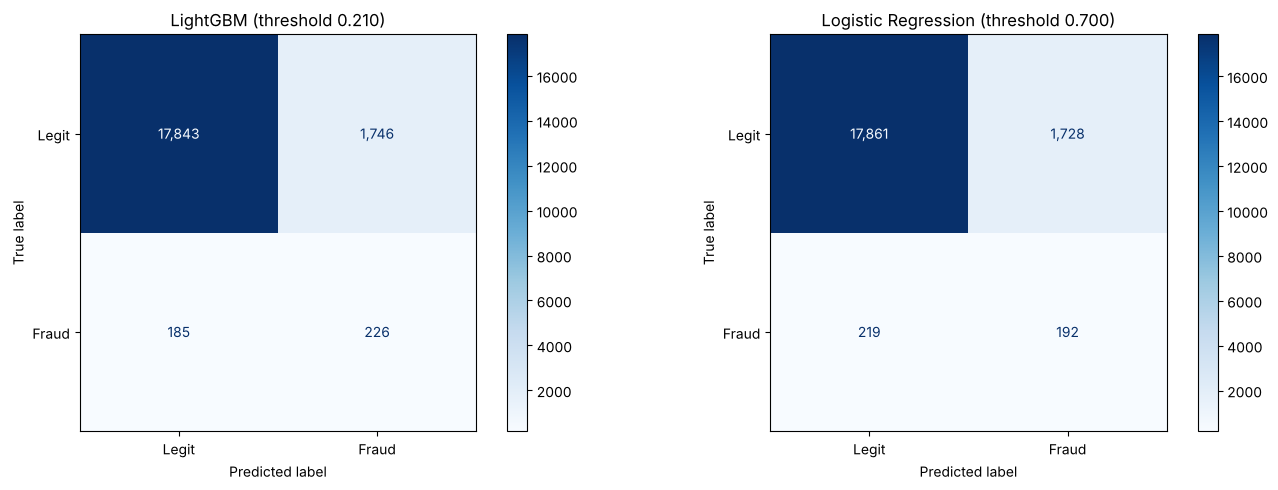

In [15]:
NAMA_FINAL = hasil_cv.loc[0, 'Model']
THRESHOLD = float(hasil_cv.loc[0, 'Threshold'])
final_model = model_terbaik[NAMA_FINAL]
proba_final = proba_test[NAMA_FINAL]
proba_lr = proba_test['Logistic Regression']
t_lr = float(hasil_cv.loc[hasil_cv['Model'] == 'Logistic Regression', 'Threshold'].iloc[0])

print(f"Model final : {NAMA_FINAL}")
print(f"Threshold   : {THRESHOLD:.3f} (biaya CV terendah)")
print(f"Parameter   : {hasil_cv.loc[0, 'Param terbaik']}")

ringkas = pd.DataFrame({
    f'{NAMA_FINAL} (final)': evaluasi(y_test, proba_final, THRESHOLD),
    'Logistic Regression (baseline tuned)': evaluasi(y_test, proba_lr, t_lr),
}).T
display(ringkas.style.format({
    'Threshold': '{:.3f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F2-Score': '{:.4f}',
    'ROC-AUC': '{:.4f}', 'PR-AUC': '{:.4f}', 'TP': '{:.0f}', 'FP': '{:.0f}', 'FN': '{:.0f}',
    'Total Biaya': '${:,.2f}', 'Biaya riil': '${:,.2f}', 'Alert per hari': '{:.1f}'}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (judul, p, t) in zip(axes, [(NAMA_FINAL, proba_final, THRESHOLD),
                                    ('Logistic Regression', proba_lr, t_lr)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= t).astype(int)),
                           display_labels=['Legit', 'Fraud']).plot(ax=ax, cmap='Blues', values_format=',')
    ax.set_title(f'{judul} (threshold {t:.3f})')
plt.tight_layout(); plt.show()

### Kurva biaya terhadap threshold (dari cross-validation di data latih)

Grafik ini menunjukkan mengapa threshold final dipilih, dan seberapa sensitif biaya terhadap pergeseran threshold. Jika kapasitas tim Fraud Authorization terbatas, geser threshold ke kanan (alert lebih sedikit, recall turun).

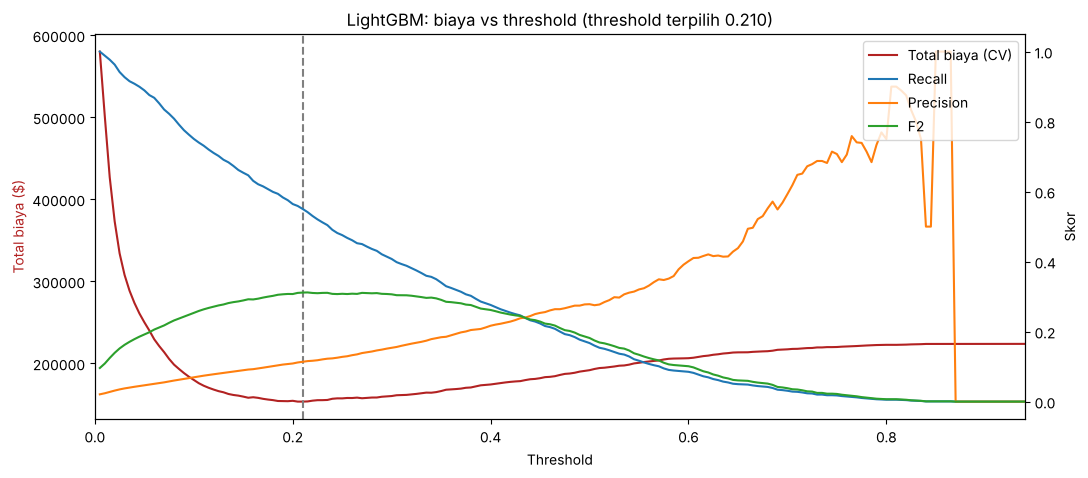

,Threshold,Precision,Recall,F2-Score,TP,FP,FN,Total Biaya,Alert per hari
0,0.100,0.0692,0.7129,0.2492,293,3941,118,"$45,626.74",58.0
1,0.200,0.1109,0.5620,0.3099,231,1852,180,"$38,402.40",28.5
2,0.210,0.1146,0.5499,0.3125,226,1746,185,"$38,288.30",27.0
3,0.300,0.1483,0.4039,0.3004,166,953,245,"$40,511.60",15.3
4,0.500,0.2646,0.1436,0.1580,59,164,352,"$49,165.36",3.1


Sensitivitas: jika TP juga dikenai biaya konfirmasi $5, threshold optimal = 0.210 (sekarang 0.210)


In [16]:
kurva = kurva_biaya[NAMA_FINAL]
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(kurva['threshold'], kurva['Total Biaya'], color='firebrick', label='Total biaya (CV)')
ax1.axvline(THRESHOLD, ls='--', color='gray')
ax1.set_xlabel('Threshold'); ax1.set_ylabel('Total biaya ($)', color='firebrick')
ax1.set_xlim(0, min(1, THRESHOLD * 4 + 0.1))
ax2 = ax1.twinx()
ax2.plot(kurva['threshold'], kurva['Recall'], label='Recall')
ax2.plot(kurva['threshold'], kurva['Precision'], label='Precision')
ax2.plot(kurva['threshold'], kurva['F2-Score'], label='F2')
ax2.set_ylabel('Skor')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88))
plt.title(f'{NAMA_FINAL}: biaya vs threshold (threshold terpilih {THRESHOLD:.3f})')
plt.show()

# Pilihan threshold lain untuk diskusi kapasitas tim (dihitung dari CV, lalu dicek di data uji)
opsi = []
for t in sorted({THRESHOLD, 0.1, 0.2, 0.3, 0.5}):
    e = evaluasi(y_test, proba_final, t)
    opsi.append({k: e[k] for k in ['Threshold', 'Precision', 'Recall', 'F2-Score', 'TP', 'FP', 'FN',
                                    'Total Biaya', 'Alert per hari']})
display(pd.DataFrame(opsi).style.format({'Threshold': '{:.3f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'F2-Score': '{:.4f}', 'Total Biaya': '${:,.2f}', 'Alert per hari': '{:.1f}'}))

# Sensitivitas: jika biaya konfirmasi $5 juga dihitung untuk setiap TP (fraud yang ditunda juga dikonfirmasi)
oof_f = oof_semua[NAMA_FINAL]
alt = kurva.assign(**{'Biaya + TP x $5': kurva['Total Biaya'] + kurva['TP'] * BIAYA_KONFIRMASI})
print(f"Sensitivitas: jika TP juga dikenai biaya konfirmasi $5, threshold optimal = "
      f"{alt.loc[alt['Biaya + TP x $5'].idxmin(), 'threshold']:.3f} (sekarang {THRESHOLD:.3f})")

## 3.5 ROC-AUC dan PR-AUC model final

- **ROC-AUC**: peluang model memberi skor lebih tinggi pada transaksi fraud dibanding transaksi legit yang dipilih acak.
- **PR-AUC**: lebih jujur untuk data tidak seimbang. Nilai acak (tanpa model) = proporsi fraud, sekitar 0,02.

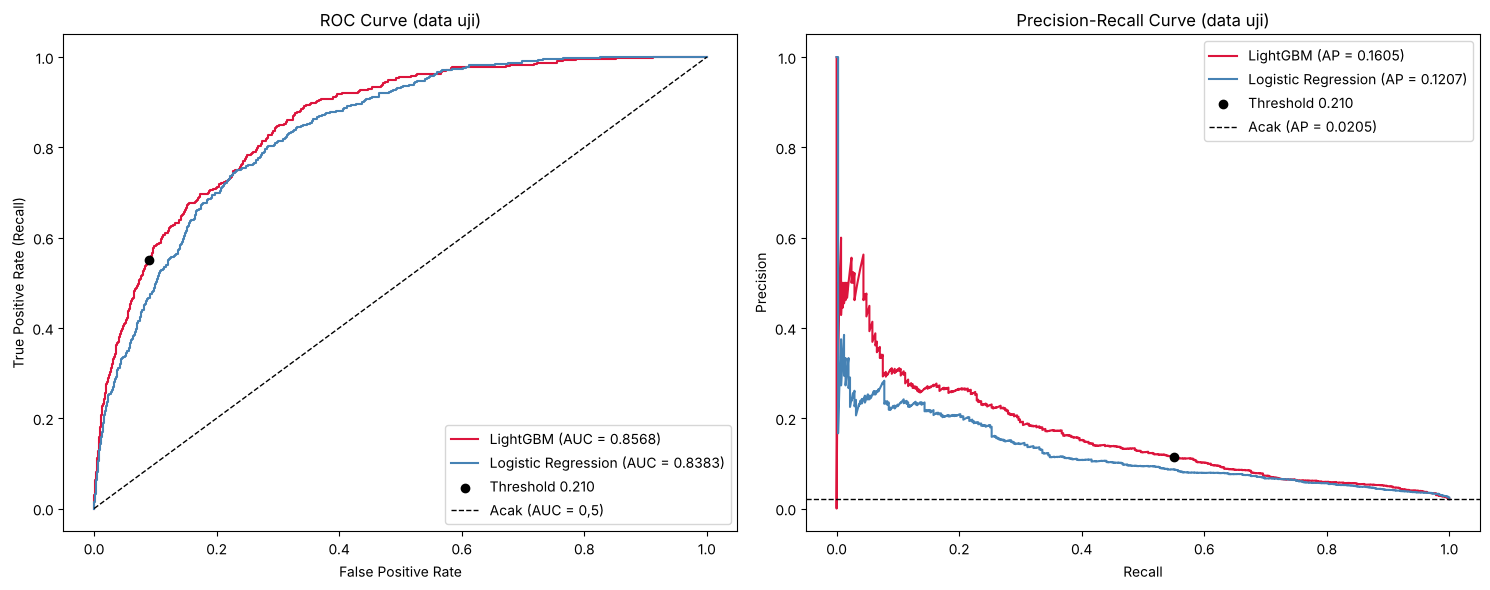

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for nama, warna in [(NAMA_FINAL, 'crimson'), ('Logistic Regression', 'steelblue')]:
    p = proba_test[nama]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=warna, label=f'{nama} (AUC = {roc_auc_score(y_test, p):.4f})')
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=warna, label=f'{nama} (AP = {average_precision_score(y_test, p):.4f})')

# titik operasi model final pada threshold terpilih
pred_final = proba_final >= THRESHOLD
tpr_t = pred_final[y_test.values == 1].mean(); fpr_t = pred_final[y_test.values == 0].mean()
axes[0].scatter(fpr_t, tpr_t, color='black', zorder=5, label=f'Threshold {THRESHOLD:.3f}')
axes[1].scatter(recall_score(y_test, pred_final), precision_score(y_test, pred_final),
                color='black', zorder=5, label=f'Threshold {THRESHOLD:.3f}')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Acak (AUC = 0,5)')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate (Recall)', title='ROC Curve (data uji)')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'Acak (AP = {y_test.mean():.4f})')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall Curve (data uji)')
for ax in axes: ax.legend(loc='best')
plt.tight_layout(); plt.show()

## 3.6 Feature Importance

Dua cara yang saling melengkapi:
1. **Importance bawaan model** (gain untuk model berbasis pohon, |koefisien| untuk model linear). Kolom hasil One-Hot dijumlahkan kembali ke kolom aslinya supaya mudah dibaca.
2. **Permutation importance** di data uji: seberapa besar PR-AUC turun jika satu kolom diacak. Cara ini tidak bias terhadap kolom dengan banyak kategori.

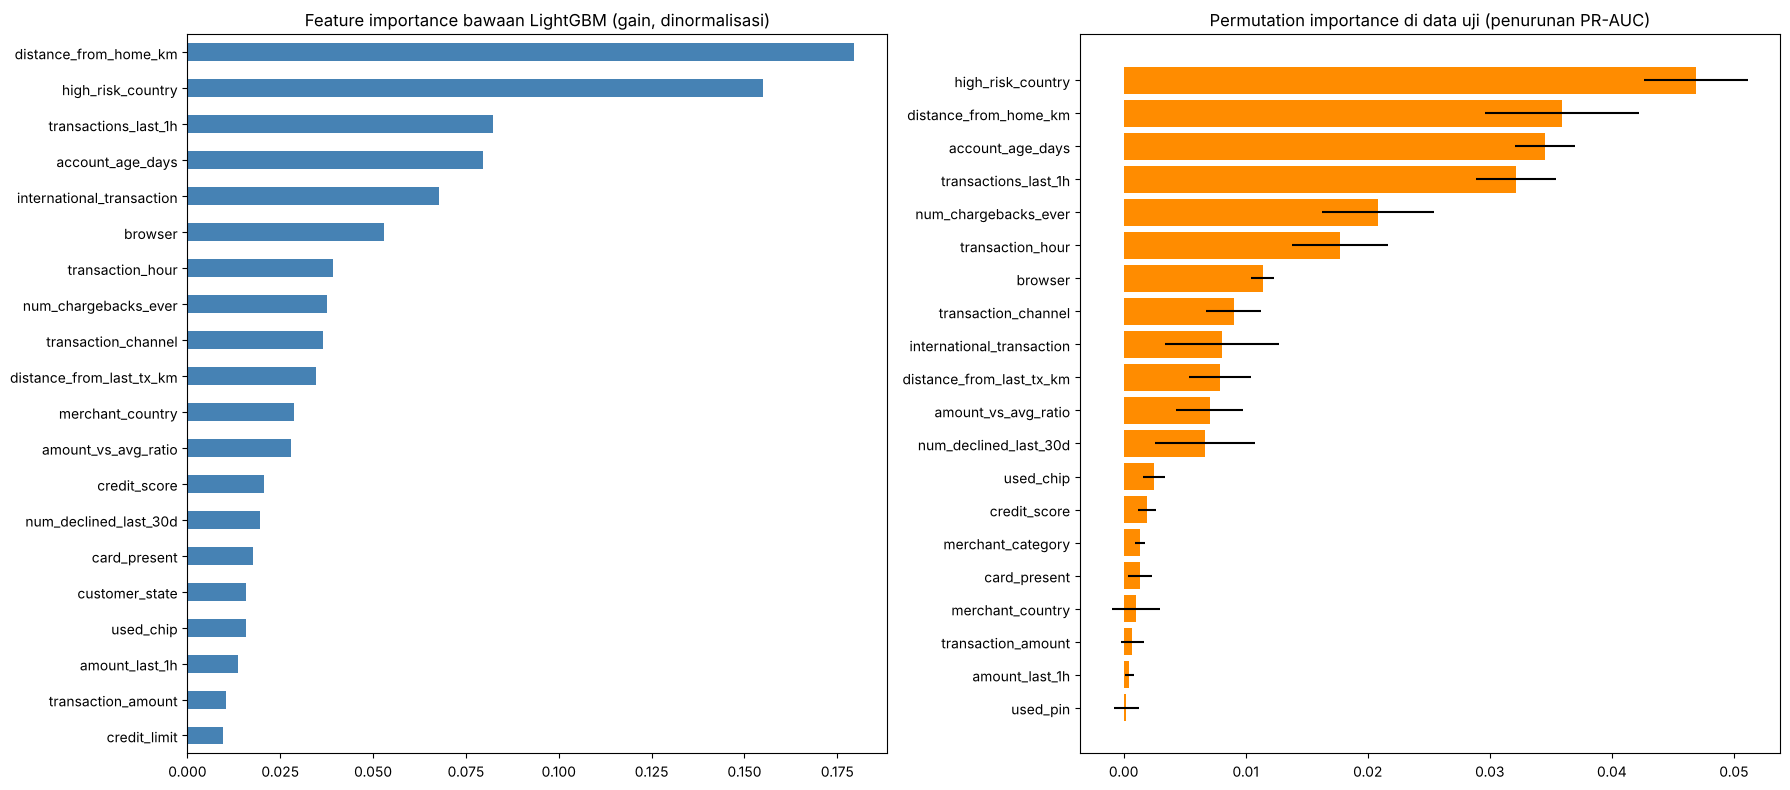

,importance_bawaan,permutation_PR-AUC
distance_from_home_km,17.95%,0.0359
high_risk_country,15.50%,0.0469
transactions_last_1h,8.24%,0.0321
account_age_days,7.96%,0.0345
international_transaction,6.77%,0.0080
browser,5.29%,0.0114
transaction_hour,3.91%,0.0177
num_chargebacks_ever,3.76%,0.0209
transaction_channel,3.65%,0.0090
distance_from_last_tx_km,3.45%,0.0079


In [18]:
prep_final = final_model.named_steps['prep']
est_final = final_model.named_steps['model']
nama_fitur = prep_final.get_feature_names_out()

# Petakan nama hasil transformasi (misal 'onehot__merchant_country_USA') ke kolom aslinya
def kolom_asli(n):
    n = n.split('__', 1)[1]
    return max([c for c in fitur_semua if n == c or n.startswith(c + '_')], key=len)
peta = np.array([kolom_asli(n) for n in nama_fitur])

if hasattr(est_final, 'feature_importances_'):
    imp = est_final.feature_importances_
    jenis = 'gain' if NAMA_FINAL in ('LightGBM', 'XGBoost') else 'impurity'
else:
    imp = np.abs(est_final.coef_[0]); jenis = '|koefisien|'
fi = pd.Series(imp, index=peta).groupby(level=0).sum()
fi = (fi / fi.sum()).sort_values(ascending=False)

perm = permutation_importance(final_model, X_test, y_test, scoring='average_precision',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
pi = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                  index=X_test.columns).sort_values('mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fi.head(20).iloc[::-1].plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title(f'Feature importance bawaan {NAMA_FINAL} ({jenis}, dinormalisasi)')
top = pi.head(20).iloc[::-1]
axes[1].barh(top.index, top['mean'], xerr=top['std'], color='darkorange')
axes[1].set_title('Permutation importance di data uji (penurunan PR-AUC)')
plt.tight_layout(); plt.show()

display(pd.DataFrame({'importance_bawaan': fi, 'permutation_PR-AUC': pi['mean']})
        .sort_values('importance_bawaan', ascending=False).head(15)
        .style.format({'importance_bawaan': '{:.2%}', 'permutation_PR-AUC': '{:.4f}'}))

## 3.7 SHAP

SHAP menjelaskan **arah** dan **besar** pengaruh setiap fitur terhadap prediksi, untuk setiap transaksi. Nilai SHAP positif mendorong prediksi ke arah fraud, negatif ke arah legit (satuan: log-odds).

**Catatan teknis:** library `shap` memakai `numba`, yang file DLL-nya bisa diblokir oleh kebijakan keamanan Windows (*Application Control policy*). Karena itu nilai SHAP di sini dihitung langsung oleh **LightGBM/XGBoost** (`pred_contrib=True`). Ini adalah algoritma TreeSHAP yang sama persis dengan `shap.TreeExplainer`, jadi hasilnya identik, tetapi tidak perlu `import shap`. Grafik dibuat dengan matplotlib.

Dihitung pada sampel 3.000 transaksi dari data uji (ditambah semua fraud di data uji supaya pola fraud terwakili).

Selisih maksimum dengan predict_proba: 0.0


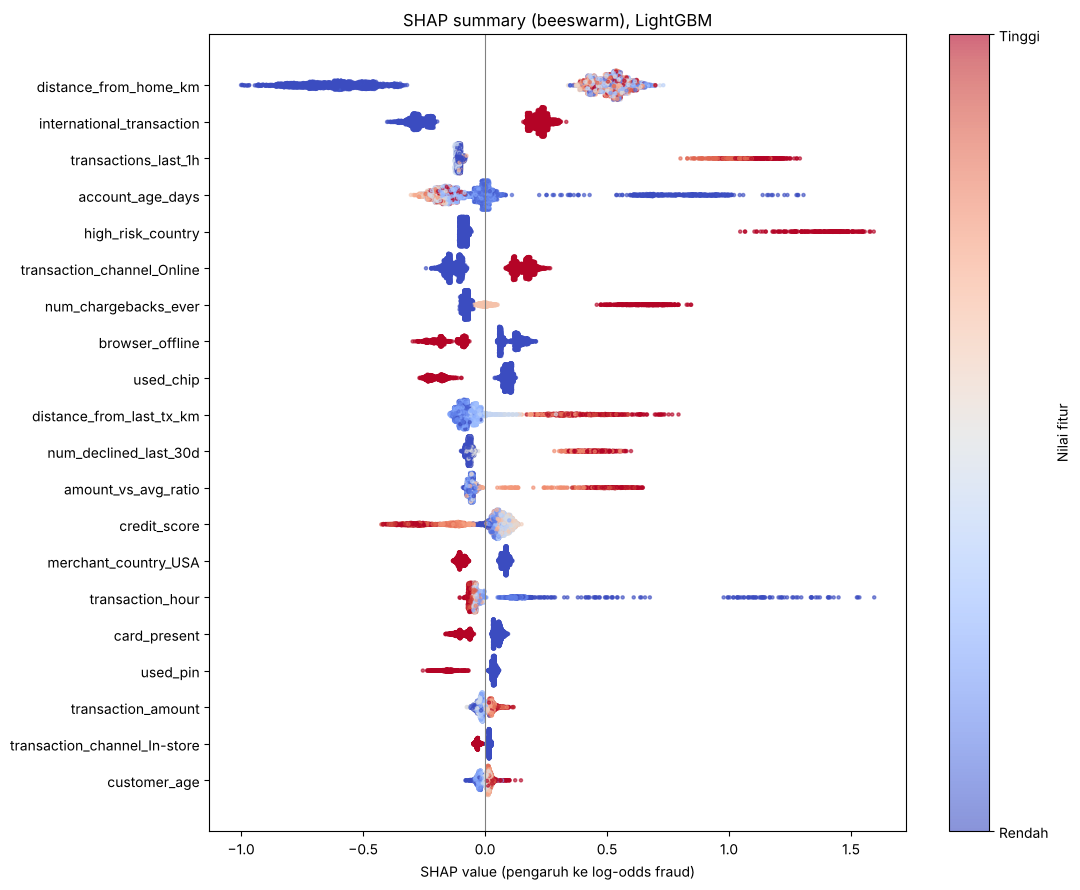

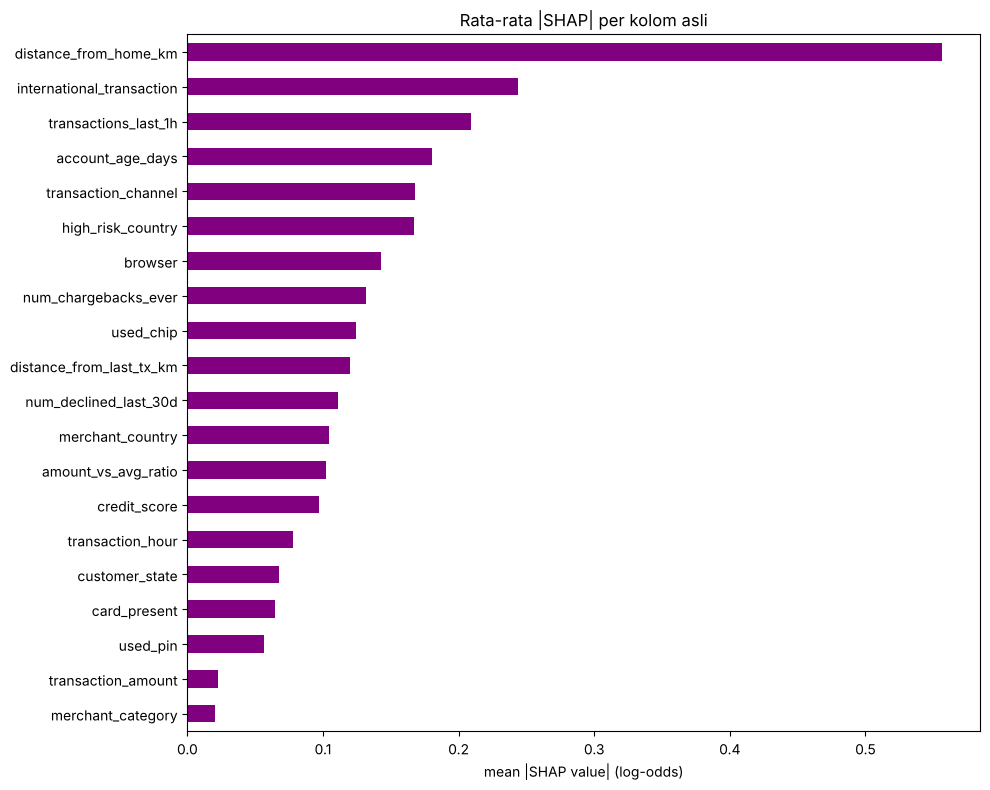

,mean |SHAP|
distance_from_home_km,0.5566
international_transaction,0.2437
transactions_last_1h,0.2089
account_age_days,0.1800
transaction_channel,0.1681
high_risk_country,0.1674
browser,0.1430
num_chargebacks_ever,0.1315
used_chip,0.1245
distance_from_last_tx_km,0.1201


In [19]:
def hitung_shap(model, X):
    """Nilai SHAP (log-odds) tanpa library shap. Mengembalikan (nilai_shap, base_value)."""
    if isinstance(model, LGBMClassifier):
        c = model.predict(X, raw_score=True, pred_contrib=True)
    elif isinstance(model, XGBClassifier):
        import xgboost as xgb
        c = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    elif isinstance(model, LogisticRegression):
        # SHAP untuk model linear dengan fitur independen: coef x (x - rata-rata data latih)
        mu = prep_final.transform(X_train).mean(axis=0)
        sv = model.coef_[0] * (X - mu)
        return sv, model.intercept_[0] + model.coef_[0] @ mu
    else:
        import shap                       # model lain (RF/HGB) tetap butuh library shap
        e = shap.TreeExplainer(model)(X)
        v = e.values[:, :, 1] if e.values.ndim == 3 else e.values
        b = e.base_values[:, 1] if np.ndim(e.base_values) == 2 else e.base_values
        return v, np.ravel(b)[0]
    return c[:, :-1], c[0, -1]

rng = np.random.RandomState(RANDOM_STATE)
idx_fraud_test = np.where(y_test.values == 1)[0]
idx_sampel = np.unique(np.concatenate([rng.choice(len(X_test), 3000, replace=False), idx_fraud_test]))
X_shap = prep_final.transform(X_test.iloc[idx_sampel])
nama_shap = [n.split('__', 1)[1] for n in nama_fitur]
sv, base_value = hitung_shap(est_final, X_shap)

# Cek: base value + jumlah SHAP = log-odds model -> probabilitas sama dengan predict_proba
p_cek = 1 / (1 + np.exp(-(base_value + sv.sum(axis=1))))
print("Selisih maksimum dengan predict_proba:", np.abs(p_cek - proba_final[idx_sampel]).max().round(6))

def plot_beeswarm(sv, X, nama, max_display=20, judul=''):
    urut = np.argsort(np.abs(sv).mean(axis=0))[::-1][:max_display][::-1]
    fig, ax = plt.subplots(figsize=(11, 9))
    for baris, j in enumerate(urut):
        v = X[:, j]
        lo, hi = np.percentile(v, [5, 95])
        warna = np.clip((v - lo) / (hi - lo), 0, 1) if hi > lo else (v > lo).astype(float)
        # jitter vertikal sebanding dengan kepadatan titik supaya mirip beeswarm
        hist, tepi = np.histogram(sv[:, j], bins=50)
        dens = hist[np.clip(np.digitize(sv[:, j], tepi) - 1, 0, 49)] / hist.max()
        yj = baris + rng.uniform(-0.4, 0.4, len(v)) * dens
        sc = ax.scatter(sv[:, j], yj, c=warna, cmap='coolwarm', s=5, alpha=0.6, vmin=0, vmax=1)
    ax.set_yticks(range(len(urut))); ax.set_yticklabels([nama[j] for j in urut])
    ax.axvline(0, color='gray', lw=0.8)
    ax.set_xlabel('SHAP value (pengaruh ke log-odds fraud)')
    cb = fig.colorbar(sc, ax=ax, ticks=[0, 1]); cb.ax.set_yticklabels(['Rendah', 'Tinggi'])
    cb.set_label('Nilai fitur')
    ax.set_title(judul); plt.tight_layout(); plt.show()

# 1) Beeswarm: 20 fitur (hasil transformasi) paling berpengaruh
plot_beeswarm(sv, X_shap, nama_shap, judul=f'SHAP summary (beeswarm), {NAMA_FINAL}')

# 2) Rata-rata |SHAP| per kolom asli (One-Hot dijumlahkan)
shap_asli = pd.DataFrame(np.abs(sv), columns=peta).T.groupby(level=0).sum().T.mean()
shap_asli = shap_asli.sort_values(ascending=False)
plt.figure(figsize=(10, 8))
shap_asli.head(20).iloc[::-1].plot.barh(color='purple')
plt.title('Rata-rata |SHAP| per kolom asli'); plt.xlabel('mean |SHAP value| (log-odds)')
plt.tight_layout(); plt.show()
display(shap_asli.head(15).to_frame('mean |SHAP|').style.format('{:.4f}'))

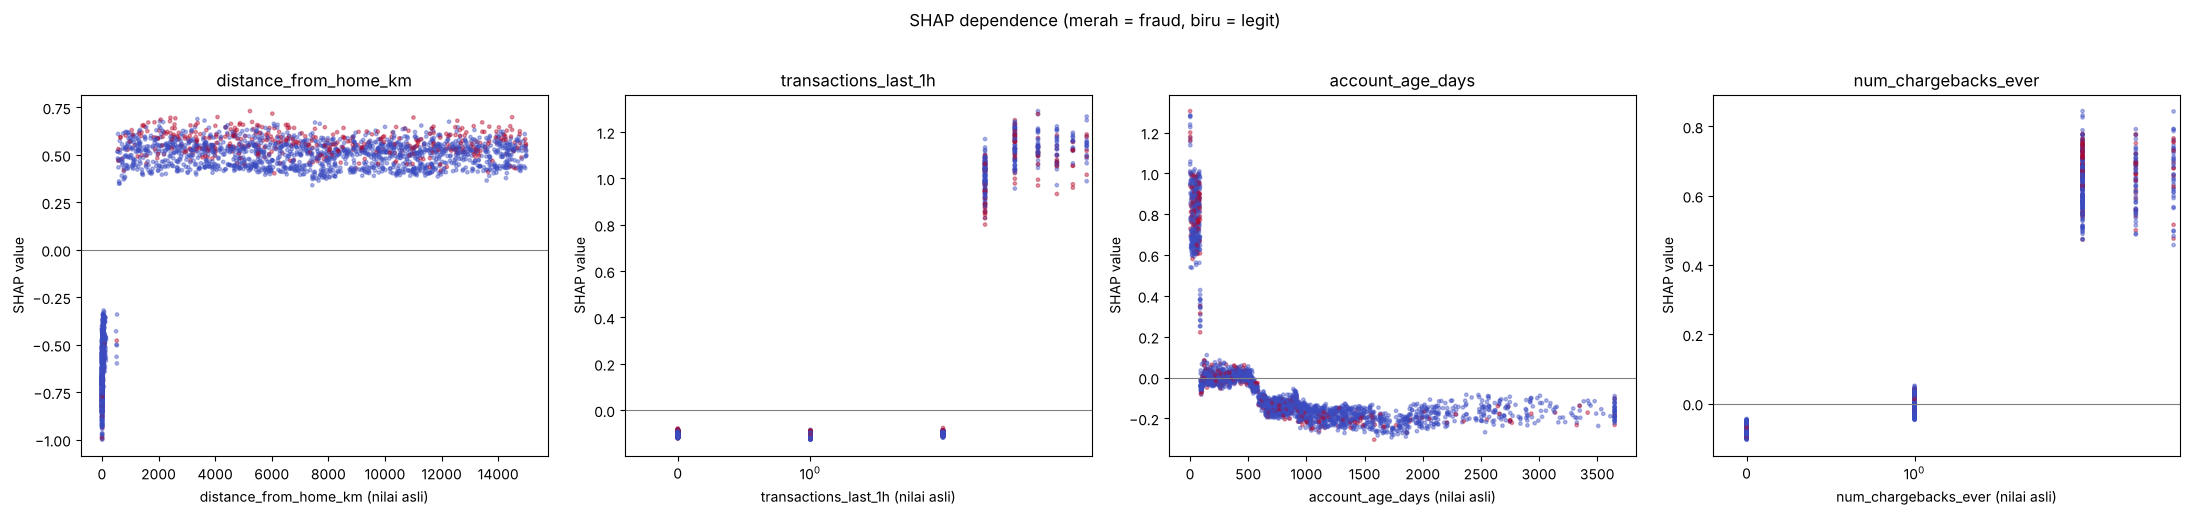

Transaksi uji #66955: probabilitas fraud 0.820 (threshold 0.210)


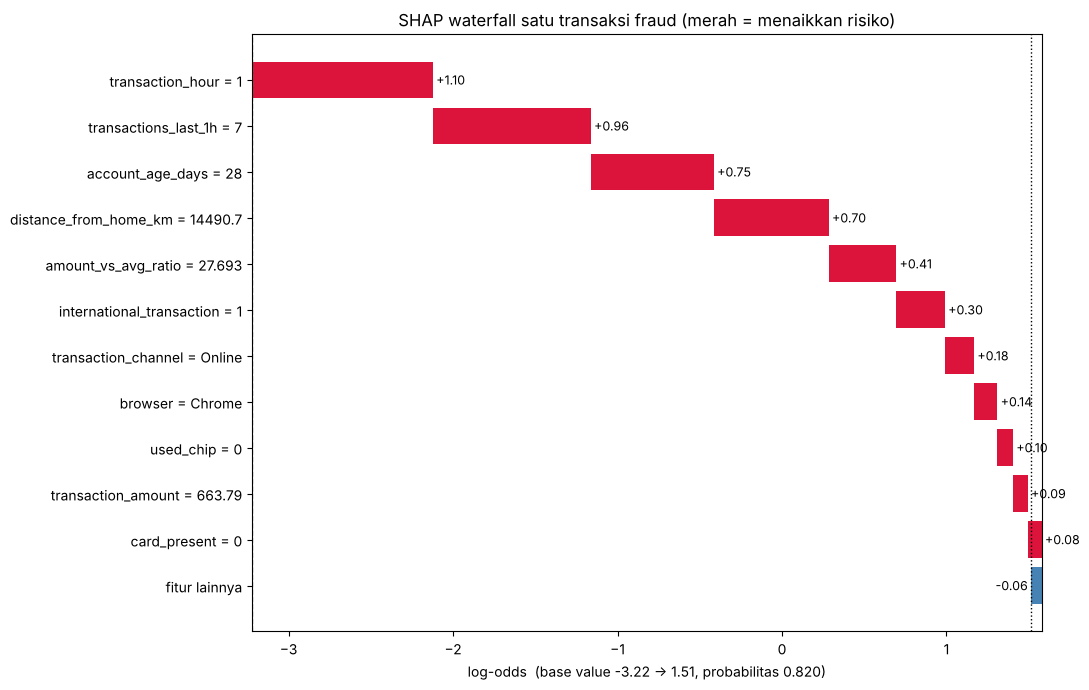

In [20]:
# 3) Dependence plot untuk 4 fitur numerik paling berpengaruh: bagaimana nilai fitur mengubah risiko
top_num = [c for c in shap_asli.index if c in kol_log + kol_scale][:4]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, c in zip(axes, top_num):
    nilai_asli = X_test.iloc[idx_sampel][c].values
    ax.scatter(nilai_asli, sv[:, nama_shap.index(c)], s=6, alpha=0.4,
               c=y_test.iloc[idx_sampel].values, cmap='coolwarm')
    ax.axhline(0, color='gray', lw=0.8)
    ax.set(xlabel=f'{c} (nilai asli)', ylabel='SHAP value', title=c)
    if c in kol_log: ax.set_xscale('symlog')
plt.suptitle('SHAP dependence (merah = fraud, biru = legit)', y=1.02)
plt.tight_layout(); plt.show()

# 4) Waterfall: penjelasan satu transaksi fraud yang tertangkap (skor tertinggi)
p_sampel = proba_final[idx_sampel]
pos = np.where((y_test.iloc[idx_sampel].values == 1) & (p_sampel >= THRESHOLD))[0]
i = pos[np.argmax(p_sampel[pos])]
baris = X_test.iloc[idx_sampel[i]]
print(f"Transaksi uji #{X_test.index[idx_sampel[i]]}: probabilitas fraud {p_sampel[i]:.3f} (threshold {THRESHOLD:.3f})")

kontribusi = pd.Series(sv[i], index=peta).groupby(level=0).sum()      # per kolom asli
kontribusi = kontribusi.reindex(kontribusi.abs().sort_values(ascending=False).index)
top = kontribusi.head(11)
top['fitur lainnya'] = kontribusi.iloc[11:].sum()
label = [f'{k} = {baris[k]}' if k in baris.index else k for k in top.index]

fig, ax = plt.subplots(figsize=(11, 7))
mulai = base_value + np.concatenate([[0], np.cumsum(top.values)[:-1]])
for r, (s, v) in enumerate(zip(mulai, top.values)):
    ax.barh(len(top) - 1 - r, v, left=s, color='crimson' if v > 0 else 'steelblue')
    ax.text(s + v + (0.02 if v > 0 else -0.02), len(top) - 1 - r, f'{v:+.2f}', va='center',
            ha='left' if v > 0 else 'right', fontsize=9)
ax.set_yticks(range(len(top))); ax.set_yticklabels(label[::-1])
ax.axvline(base_value, color='gray', ls='--', lw=1)
akhir = base_value + top.sum()
ax.axvline(akhir, color='black', ls=':', lw=1)
ax.set_xlabel(f'log-odds  (base value {base_value:.2f} -> {akhir:.2f}, probabilitas {1/(1+np.exp(-akhir)):.3f})')
ax.set_title('SHAP waterfall satu transaksi fraud (merah = menaikkan risiko)')
plt.tight_layout(); plt.show()

## 3.8 Simpan model final

Model disimpan bersama threshold dan asumsi biaya supaya bisa dipakai ulang tanpa melatih ulang.

In [21]:
os.makedirs('../models', exist_ok=True) if os.path.basename(os.getcwd()) == 'notebooks' else None
path_model = '../models/fraud_model_final.joblib' if os.path.isdir('../models') else 'fraud_model_final.joblib'
joblib.dump({'model': final_model, 'threshold': THRESHOLD, 'fitur': fitur_semua,
             'biaya_fn': BIAYA_FN, 'biaya_fp': BIAYA_FP, 'nama_model': NAMA_FINAL}, path_model)
print("Model disimpan di:", os.path.abspath(path_model))

Model disimpan di: /tmp/claude-0/-home-user/36594ae5-9aff-58eb-9d88-c569503fe14f/scratchpad/w/models/fraud_model_final.joblib


# 4 RINGKASAN PERBAIKAN DAN KESIMPULAN

### Perbaikan perhitungan
| Bagian | Masalah di versi lama | Perbaikan |
|---|---|---|
| 1 Import | `numpy` di-import dua kali; library model dan metrik tambahan belum ada | Import dirapikan |
| 2.1 Outlier | `num_chargebacks_ever` punya IQR = 0, sehingga **semua nilai selain 0 (22,97%) dianggap outlier**. Batas bawah negatif untuk kolom yang tidak mungkin negatif | Kolom dengan IQR = 0 ditandai "metode IQR tidak berlaku"; batas bawah dipotong di 0; ditambah cek min/max kontekstual dan whisker boxplot disamakan 3,0 x IQR |
| 2.2-2.3 Uji statistik | Uji dijalankan di **seluruh data** (termasuk data uji) lalu dipakai memilih fitur: *leakage* | Data dibagi dulu, uji hanya di data latih |
| 2.3 Chi-square | Koreksi Yates (default) membuat Cramér's V kolom biner sedikit terlalu kecil | `correction=False` untuk effect size |
| 2.3 Signifikansi | 35 uji tanpa koreksi uji berganda | Ditambah kolom signifikan setelah koreksi Bonferroni |
| 3 Biaya | Angka diketik manual | Diverifikasi dari data (semua angka sudah benar); catatan bahwa $7,50 adalah perkiraan atas |
| 3.1 Preprocessing | `buat_preprocessor` versi pertama tidak terpakai; `fit_transform` di seluruh data termasuk data uji dan kolom target; daftar kolom ditulis dua kali | Fungsi duplikat dihapus, fit hanya di data latih |
| 3.2 Baseline | Hanya Precision/Recall/F2 pada threshold 0,5, sehingga KNN dan Random Forest terlihat "nol" karena threshold, bukan karena tidak ada sinyal | Ditambah ROC-AUC dan PR-AUC; perbandingan adil di 3.3 |
| 3.3 Threshold | Threshold tetap 0,5 | Threshold dipilih dari biaya terendah pada prediksi cross-validation data latih, bukan data uji |
| 3.7 SHAP | `import shap` gagal di Windows karena DLL numba diblokir Application Control policy | SHAP dihitung langsung oleh LightGBM (`pred_contrib=True`, algoritma TreeSHAP yang sama), tanpa library shap |

### Kesimpulan (hasil eksekusi notebook ini)
**Model final: LightGBM** (num_leaves=7, min_child_samples=200, learning_rate=0,02, n_estimators=500, scale_pos_weight=5), **threshold 0,21**.

| Data uji (20.000 transaksi) | LightGBM (final) | Logistic Regression (tuned) |
|---|---|---|
| Precision | 0,1146 | 0,1000 |
| Recall | 0,5499 | 0,4672 |
| F2-Score | **0,3125** | 0,2694 |
| ROC-AUC | **0,8568** | 0,8383 |
| PR-AUC | **0,1605** | 0,1207 |
| TP / FP / FN | 226 / 1.746 / 185 | 192 / 1.728 / 219 |
| Total biaya (FN x 136,18 + FP x 7,50) | **$38.288** | $42.783 |
| Alert per hari | ~27 | ~26 |

- Tanpa model (semua fraud lolos) biaya di data uji $55.970, jadi model final **menghemat sekitar 31,6%**.
- Tiga model Gradient Boosting (LightGBM, XGBoost, HistGradientBoosting) konsisten di atas model lain, baik di cross-validation maupun data uji. Perbedaan di antara ketiganya kecil.
- Fitur paling berpengaruh (SHAP): `distance_from_home_km`, `international_transaction`, `transactions_last_1h`, `account_age_days`, `transaction_channel`, `high_risk_country`. Risiko naik saat transaksi jauh dari rumah, lintas negara/negara berisiko tinggi, banyak transaksi dalam 1 jam, akun masih baru, dan online.
- Catatan jujur: jika memakai kerugian **riil** per transaksi (`fraud_amount_lost`), Logistic Regression ($34.664) sedikit lebih murah daripada LightGBM ($35.715), karena fraud yang lolos dari LR kebetulan bernominal kecil. Selisihnya kecil dan model dipilih dari biaya cross-validation, bukan data uji.
- Sinyal data memang lemah (PR-AUC 0,16; precision sekitar 11%), jadi sekitar 9 dari 10 alert adalah transaksi legit. Pastikan tim Fraud Authorization sanggup sekitar 27 konfirmasi per hari; jika tidak, naikkan threshold (misal 0,30 = ~15 alert per hari, recall 0,40). Angka $5 biaya konfirmasi masih asumsi; jika biaya riil berbeda, cukup ubah `BIAYA_KONFIRMASI`/`BIAYA_FP` lalu jalankan ulang untuk mendapatkan threshold baru.